# Sesión 6/6 · Aprendizaje no supervisado y detección de anomalías
**IA aplicada a la ciberseguridad · Máster en Ciberseguridad**  
**Edición didáctica: explicaciones progresivas, salidas interpretables y todos los retos originales resueltos.**

**Problema:** en una red real no siempre contamos con ejemplos etiquetados como «normal» o «ataque». ¿Podemos encontrar comportamientos que se desvían de lo habitual y decidir qué merece investigar?

| Parte | Técnica | Pregunta que responderemos |
|---|---|---|
| **A** | k-means | ¿Cómo aparecen grupos sin conocer las categorías de ataque? |
| **B** | DBSCAN | ¿Cómo identificar regiones densas y puntos aislados sin fijar el número de grupos? |
| **C** | PCA y reconstrucción | ¿Cuándo un tráfico no encaja con los patrones del tráfico normal? |
| **D** | Isolation Forest, LOF y One-Class SVM | ¿Cómo se comparan detectores de anomalías diferentes? |
| **E** | Registros SSH | ¿Qué sesiones parecen raras si solo tenemos un `auth.log`? |
| **F** | z clásico y robusto | ¿Puede una anomalía alterar la estadística utilizada para detectarla? |
| **G** | Presupuesto de alertas | Si solo podemos revisar 100 alertas, ¿cuáles revisamos primero? |

**Regla fundamental del cuaderno:** los modelos no supervisados **no reciben las etiquetas de ataque durante el ajuste**. Algunos métodos aprenden con todos los datos sin etiqueta (A y B) y otros se ajustan **solo con tráfico normal** (C y D). Cuando disponemos de etiquetas en estos conjuntos didácticos, se usan **después** para evaluar el detector, nunca para calcular sus patrones no supervisados.

**Ruta base original:** A, C, D, F y G. **Ruta avanzada original:** B, E y los retos. Esta edición resuelve ambas rutas. Ejecuta las celdas en orden (`Mayús + Intro`). Si reinicias el kernel, vuelve a ejecutar desde «Preparación».

## Antes de empezar · Diferenciar clasificación, agrupamiento y anomalía

Imagina 1.000 conexiones de red, cada una descrita por variables como duración, bytes recibidos y número de errores:

- **Clasificación supervisada:** el entrenamiento conoce si cada conexión es normal (`0`) o ataque (`1`); aprende a distinguir ambas clases. Es lo que hicimos en sesiones anteriores.
- **Agrupamiento (*clustering*):** solo recibe características, sin etiquetas. Busca conexiones parecidas y las agrupa. Un clúster no es «malicioso» por definición: podría contener copias de seguridad nocturnas, escaneos autorizados o muchos ataques similares.
- **Detección de anomalías:** asigna una *puntuación* que refleja lo inusual de una observación según un criterio. Una conexión rara no es necesariamente un ataque y una conexión maliciosa puede parecer normal.

**Ejemplo:** un servidor hace normalmente 10 consultas DNS por minuto; hoy realiza 80. El cambio es una **anomalía**. Puede ser una exfiltración, pero también una actualización masiva o una herramienta de inventario. Para determinar la causa hacen falta registros y contexto adicional.

**Vocabulario de evaluación (lo reutilizaremos en cada sección):**

- **`train` / entrenamiento:** ejemplos con los que se aprenden parámetros del modelo. **`test` / prueba:** ejemplos reservados para comprobar cómo se comporta con datos distintos.
- **TP:** ataques correctamente marcados; **FP:** conexiones normales marcadas como ataque; **FN:** ataques no detectados; **TN:** normales correctamente descartados.
- **Recall / sensibilidad:** `TP / (TP + FN)`. De cada 100 ataques reales, ¿cuántos detectamos?
- **Tasa de falsas alarmas (FPR):** `FP / (FP + TN)`. De cada 100 conexiones normales, ¿cuántas molestan al analista?
- **Precision:** `TP / (TP + FP)`. De las alertas que revisamos, ¿cuántas eran ataques?
- **ROC AUC:** mide si el detector tiende a dar más puntuación de anomalía a ataques que a normales cuando comparamos distintos umbrales. `0,5` es equivalente a una ordenación aleatoria; `1` es perfecta. No indica directamente el porcentaje de ataques detectados.
- **AP (*average precision*):** resume cómo cambian precisión y recall al recorrer los umbrales. Es especialmente útil cuando hay pocos ataques: una AP de `0,20` no significa necesariamente «20 % de acierto».

Si hay **80 ataques y 920 normales**, y un sistema alerta de **100 conexiones**, de las cuales **60** eran ataques: `precision = 60/100 = 60 %`, `recall = 60/80 = 75 %`, `FPR = 40/920 ≈ 4,35 %`. Estas métricas contestan preguntas **diferentes**.

## Preparación · Bibliotecas, utilidades y datos

**Objetivo:** garantizar que todas las partes utilicen el mismo conjunto de datos y la misma transformación de las características. `numpy` calcula con números y matrices, `pandas` representa tablas, `matplotlib` dibuja gráficos y `scikit-learn` contiene algoritmos de ML.

La siguiente celda solo instala paquetes cuando faltan. Como en el original, también comprueba `xgboost` y `lightgbm` para mantener las dependencias del curso; **no se entrenan** aquí. Las instalaciones necesitan conexión a Internet, pero si los paquetes ya existen no se descargan de nuevo.

In [1]:
# 1) Comprobar paquetes sin importarlos todos antes de tiempo.
import importlib.util
import subprocess
import sys

EN_COLAB = 'google.colab' in sys.modules
paquetes = {
    'numpy': 'numpy',
    'pandas': 'pandas',
    'sklearn': 'scikit-learn',
    'matplotlib': 'matplotlib',
    'seaborn': 'seaborn',
    'joblib': 'joblib',
    'xgboost': 'xgboost',
    'lightgbm': 'lightgbm',
}

faltan = [nombre_pip for modulo, nombre_pip in paquetes.items()
          if importlib.util.find_spec(modulo) is None]
print('=== PREPARACIÓN · ENTORNO ===')
print('Entorno:', 'Google Colab' if EN_COLAB else 'Jupyter / VS Code / Codespaces')
if faltan:
    print('Instalando paquetes ausentes:', ', '.join(faltan))
    # sys.executable instala paquetes en el mismo Python que ejecuta el notebook.
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *faltan])
else:
    print('Bibliotecas: todas las dependencias del curso están disponibles.')

=== PREPARACIÓN · ENTORNO ===
Entorno: Jupyter / VS Code / Codespaces
Bibliotecas: todas las dependencias del curso están disponibles.


### Crear las funciones auxiliares originales del curso

El primer bloque guarda `ia_utils.py`, un **archivo Python importable**, en la carpeta de trabajo. Es exactamente el módulo auxiliar del notebook original; contiene funciones para descargar **NSL-KDD**, traducir etiquetas de ataques a categorías y generar/analizar un `auth.log` sintético. No altera un archivo personal llamado `utils.py`.

**Cómo funciona:** una cadena de texto contiene el código fuente; `Path('ia_utils.py').write_text(...)` lo escribe y `importlib.reload` recarga sus funciones si volvemos a ejecutar la sesión. La escritura **sustituye** el contenido anterior en vez de añadir líneas en cada ejecución: por tanto, una segunda ejecución no duplica funciones.

**Dependencia externa:** si no existen `data/KDDTrain+.txt` y `data/KDDTest+.txt`, `load_nsl_kdd` intenta descargarlos del repositorio público configurado en el módulo. Necesitarás conexión solo esa primera vez; si ya los guardaste de otra sesión, se reutilizan.

In [ ]:
# 2) Guardar exactamente las utilidades entregadas por el curso en un módulo importable.
# La cadena IA_UTILS es código fuente; no son datos de NSL-KDD.
from pathlib import Path
import importlib

IA_UTILS = r'''"""Funciones del curso IA aplicada a la ciberseguridad (sesiones 3 a 6)."""
import os, re, urllib.request
import numpy as np
import pandas as pd

NSL_URL = "https://raw.githubusercontent.com/defcom17/NSL_KDD/master/"
NSL_COLS = ["duration","protocol_type","service","flag","src_bytes","dst_bytes","land",
  "wrong_fragment","urgent","hot","num_failed_logins","logged_in","num_compromised",
  "root_shell","su_attempted","num_root","num_file_creations","num_shells",
  "num_access_files","num_outbound_cmds","is_host_login","is_guest_login","count",
  "srv_count","serror_rate","srv_serror_rate","rerror_rate","srv_rerror_rate",
  "same_srv_rate","diff_srv_rate","srv_diff_host_rate","dst_host_count",
  "dst_host_srv_count","dst_host_same_srv_rate","dst_host_diff_srv_rate",
  "dst_host_same_src_port_rate","dst_host_srv_diff_host_rate","dst_host_serror_rate",
  "dst_host_srv_serror_rate","dst_host_rerror_rate","dst_host_srv_rerror_rate",
  "label","difficulty"]


def load_nsl_kdd(split="train", base="data"):
    """Carga NSL-KDD y añade la columna is_attack. Descarga los ficheros si faltan."""
    name = "KDDTrain+.txt" if split == "train" else "KDDTest+.txt"
    path = os.path.join(base, name)
    if not os.path.exists(path):
        os.makedirs(base, exist_ok=True)
        urllib.request.urlretrieve(NSL_URL + name.replace("+", "%2B"), path)
    df = pd.read_csv(path, header=None, names=NSL_COLS)
    df["is_attack"] = (df["label"] != "normal").astype(int)
    return df


ATTACK_MAP = {"normal": "normal",
  **{a: "dos" for a in ["back", "land", "neptune", "pod", "smurf", "teardrop",
                        "apache2", "udpstorm", "processtable", "mailbomb"]},
  **{a: "probe" for a in ["satan", "ipsweep", "nmap", "portsweep", "mscan", "saint"]},
  **{a: "r2l" for a in ["guess_passwd", "ftp_write", "imap", "phf", "multihop",
                        "warezmaster", "warezclient", "spy", "xlock", "xsnoop",
                        "snmpguess", "snmpgetattack", "httptunnel", "sendmail",
                        "named", "worm"]},
  **{a: "u2r" for a in ["buffer_overflow", "loadmodule", "rootkit", "perl",
                        "sqlattack", "xterm", "ps"]}}


def add_category(df):
    """Añade la columna category: normal, dos, probe, r2l o u2r."""
    df["category"] = df["label"].map(ATTACK_MAP)
    return df


def generar_flujos(n=60_000, frac_ataque=0.25, seed=0, cambio_herramienta=False):
    """Flujos de red sintéticos con columnas al estilo CICIDS2017, incluidos sus defectos
    (espacios en los nombres, infinitos, nulos y duplicados). Etiquetas BENIGN / DDoS.
    Con cambio_herramienta=True el ataque llega en dos episodios con herramientas distintas."""
    rng = np.random.default_rng(seed)
    nb, na = int(n * (1 - frac_ataque)), int(n * frac_ataque)
    t0 = pd.Timestamp("2017-07-07 09:00:00")
    # --- tráfico benigno
    port_b = rng.choice([443, 80, 53, 22, 8080, 3389, 0], nb, p=[.40, .20, .20, .05, .05, .02, .08])
    port_b = np.where(port_b == 0, rng.integers(1024, 65535, nb), port_b)
    dur_b = np.where(rng.random(nb) < 0.02, 0, rng.lognormal(11, 2, nb)).astype(int)
    fwd_b = rng.poisson(8, nb) + 1
    bwd_b = rng.poisson(7, nb)
    fwl_b = np.where(rng.random(nb) < 0.15, rng.uniform(0, 10, nb), rng.normal(400, 250, nb)).clip(0)
    bwl_b = rng.normal(700, 400, nb).clip(0)
    syn_b = (rng.random(nb) < 0.3).astype(int)
    win_b = rng.choice([29200, 65535, 8192, 14600, 64240, -1], nb, p=[.25, .25, .15, .1, .15, .1])
    ts_b = rng.uniform(0, 8 * 3600, nb)
    # --- ataque
    if cambio_herramienta:
        epi = rng.random(na) < 0.5
        ts_a = np.where(epi, rng.uniform(1 * 3600, 2 * 3600, na), rng.uniform(5 * 3600, 6 * 3600, na))
        port_a = np.where(epi, 80, rng.choice([8080, 443], na))
        win_a = np.where(epi, 8192, rng.choice([29200, 65535, 64240], na))
        fwl_a = np.where(epi, rng.normal(8, 6, na), rng.normal(60, 40, na)).clip(0)
    else:
        ts_a = rng.uniform(6.9 * 3600, 7.3 * 3600, na)
        port_a = np.where(rng.random(na) < 0.9, 80, 443)
        win_a = np.where(rng.random(na) < 0.95, 8192, 29200)
        fwl_a = rng.normal(8, 6, na).clip(0)
    dur_a = rng.lognormal(13, 1.5, na).astype(int)
    fwd_a = rng.poisson(4, na) + 1
    bwd_a = rng.poisson(3, na)
    bwl_a = rng.normal(1500, 600, na).clip(0)
    syn_a = (rng.random(na) < 0.6).astype(int)

    def bloque(port, dur, fwd, bwd, fwl, bwl, syn, win, ts, label):
        tot_f, tot_b = fwd * fwl, bwd * bwl
        seg = np.maximum(dur, 0) / 1e6
        with np.errstate(divide="ignore", invalid="ignore"):
            fbs = (tot_f + tot_b) / seg
            fps = (fwd + bwd) / seg
            iat = np.where(fwd + bwd > 1, dur / np.maximum(fwd + bwd - 1, 1), np.nan)
        return pd.DataFrame({
            " Destination Port": port, " Flow Duration": dur, " Total Fwd Packets": fwd,
            " Total Backward Packets": bwd, "Total Length of Fwd Packets": tot_f.round(1),
            " Total Length of Bwd Packets": tot_b.round(1), " Fwd Packet Length Mean": fwl.round(2),
            " Bwd Packet Length Mean": bwl.round(2), "Flow Bytes/s": fbs, " Flow Packets/s": fps,
            " Flow IAT Mean": iat, " SYN Flag Count": syn, " ACK Flag Count": (rng.random(len(port)) < 0.85).astype(int),
            "Init_Win_bytes_forward": win, " Avg Fwd Segment Size": fwl.round(2),
            " Timestamp": t0 + pd.to_timedelta(ts, unit="s"), " Label": label})

    df = pd.concat([bloque(port_b, dur_b, fwd_b, bwd_b, fwl_b, bwl_b, syn_b, win_b, ts_b, "BENIGN"),
                    bloque(port_a, dur_a, fwd_a, bwd_a, fwl_a, bwl_a, syn_a, win_a, ts_a, "DDoS")], ignore_index=True)
    df.loc[rng.random(len(df)) < 0.001, "Flow Bytes/s"] = np.nan
    df = pd.concat([df, df.sample(frac=0.01, random_state=seed)], ignore_index=True)
    return df.sort_values(" Timestamp").reset_index(drop=True)


def generar_authlog(ruta="auth.log", n_atacantes=12, seed=42):
    """auth.log sintético de la sesión 2: 40 IP legítimas y n_atacantes IP de fuerza bruta (203.0.113.0/24)."""
    import datetime as dt
    rng = np.random.default_rng(seed); start = dt.datetime(2026, 10, 1)
    users = ["root", "admin", "carlos", "ana", "luis", "deploy", "test", "oracle", "ubuntu", "postgres"]
    rows = []
    for i in range(40):
        ip = f"10.10.10.{10 + i}"
        for t in rng.uniform(0, 7 * 24 * 3600, rng.integers(5, 40)):
            rows.append((start + dt.timedelta(seconds=float(t)), bool(rng.random() > 0.08), str(rng.choice(users[2:6])), ip))
    for i in range(n_atacantes):
        ip = f"203.0.113.{20 + i}"; t0 = rng.uniform(0, 7 * 24 * 3600 - 3600)
        for t in t0 + np.sort(rng.uniform(0, 1800, rng.integers(60, 400))):
            rows.append((start + dt.timedelta(seconds=float(t)), False, str(rng.choice(users)), ip))
    rows.sort(key=lambda r: r[0])
    with open(ruta, "w") as f:
        for ts, ok, user, ip in rows:
            v = "Accepted" if ok else "Failed"
            f.write(f"{ts:%b %d %H:%M:%S} srv sshd[{rng.integers(1000, 9999)}]: {v} password "
                    f"for {user} from {ip} port {rng.integers(1024, 65000)} ssh2\n")
    return ruta


def auth_features(ruta="auth.log"):
    """Características por IP y ventana de 10 minutos. La columna verdad solo sirve para evaluar."""
    pat = re.compile(r"^(\w{3}\s+\d+ \d\d:\d\d:\d\d) \S+ sshd\[\d+\]: (Failed|Accepted) password for (\S+) from (\S+) port")
    reg = []
    for linea in open(ruta):
        m = pat.match(linea)
        if m:
            reg.append((pd.to_datetime("2026 " + m.group(1), format="%Y %b %d %H:%M:%S"),
                        m.group(2) == "Accepted", m.group(3), m.group(4)))
    log = pd.DataFrame(reg, columns=["ts", "ok", "user", "ip"])
    log["win"] = log["ts"].dt.floor("10min")
    f = log.groupby(["ip", "win"]).agg(n=("ok", "size"), n_ok=("ok", "sum"), n_users=("user", "nunique")).reset_index()
    f["n_fail"] = f["n"] - f["n_ok"]
    f["fail_ratio"] = f["n_fail"] / f["n"]
    f["verdad"] = f["ip"].str.startswith("203.0.113.").astype(int)
    return f
'''
Path('ia_utils.py').write_text(IA_UTILS, encoding='utf-8')

# 3) Importar las funciones auxiliares que utilizarán las demás secciones.
import ia_utils
importlib.reload(ia_utils)
from ia_utils import load_nsl_kdd, add_category, generar_flujos
print('=== FUNCIONES DISPONIBLES ===')
print('Módulo ia_utils.py creado / actualizado sin duplicaciones.')
print('Funciones: load_nsl_kdd · add_category · generar_flujos')

=== FUNCIONES DISPONIBLES ===
Módulo ia_utils.py creado / actualizado sin duplicaciones.
Funciones: load_nsl_kdd · add_category · generar_flujos


### Datos de entrada: qué representa cada fila

**NSL-KDD** describe conexiones de red. `load_nsl_kdd('train')` carga conexiones de entrenamiento y `load_nsl_kdd('test')` otras conexiones para evaluación. La columna `label` contiene el nombre de la actividad (por ejemplo, `normal` o una técnica de ataque) y `is_attack` vale `0` en una conexión normal y `1` en una conexión etiquetada como ataque.

`add_category` agrupa las etiquetas de origen en cinco categorías: `normal`, `dos` (denegación de servicio), `probe` (reconocimiento), `r2l` (acceso remoto a cuenta local) y `u2r` (escalada desde usuario a root). Estas **etiquetas son solo para interpretar o evaluar**: no entrarán en las variables de entrenamiento no supervisado.

**Una fila = una conexión; una columna = una propiedad.** El conjunto de 17 propiedades numéricas `num` se define en la parte A y será la entrada común de los modelos. Se excluyen expresamente `label`, `category` e `is_attack`.

In [3]:
# 3) Cargar los ficheros de NSL-KDD y añadir etiquetas SOLO informativas.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from IPython.display import display

plt.rcParams['figure.figsize'] = (9, 4)

tr = add_category(load_nsl_kdd('train'))
te = add_category(load_nsl_kdd('test'))

print('=== DATOS · NSL-KDD ===')
print(f'Entrenamiento: {len(tr):,} conexiones, {tr.shape[1]} columnas')
print(f'Prueba:        {len(te):,} conexiones, {te.shape[1]} columnas')
print(f'scikit-learn: {sklearn.__version__}')

# Verificar que las etiquetas de evaluación NO faltan silenciosamente.
print('\nRecuento de conexiones por categoría de origen:')
display(pd.DataFrame({
    'Entrenamiento (conexiones)': tr['category'].value_counts(),
    'Prueba (conexiones)': te['category'].value_counts(),
}).fillna(0).astype(int).rename_axis('Categoría'))

print('\nEjemplo de 3 conexiones · columnas ilustrativas (no son predicciones):')
display(tr[['duration', 'src_bytes', 'dst_bytes', 'count',
            'label', 'category', 'is_attack']].head(3).rename(columns={
                'duration': 'Duración (s)',
                'src_bytes': 'Bytes enviados',
                'dst_bytes': 'Bytes recibidos',
                'count': 'Conexiones relacionadas',
                'label': 'Etiqueta original',
                'category': 'Familia',
                'is_attack': '¿Ataque? (1=sí)',
            }))

=== DATOS · NSL-KDD ===
Entrenamiento: 125,973 conexiones, 45 columnas
Prueba:        22,544 conexiones, 45 columnas
scikit-learn: 1.9.1

Recuento de conexiones por categoría de origen:


,Entrenamiento (conexiones),Prueba (conexiones)
Categoría,,
dos,45927,7458
normal,67343,9711
probe,11656,2421
r2l,995,2887
u2r,52,67



Ejemplo de 3 conexiones · columnas ilustrativas (no son predicciones):


,Duración (s),Bytes enviados,Bytes recibidos,Conexiones relacionadas,Etiqueta original,Familia,¿Ataque? (1=sí)
0,0,491,0,2,normal,normal,0
1,0,146,0,13,normal,normal,0
2,0,0,0,123,neptune,dos,1


**Cómo leer estas salidas:** las dimensiones (`filas × columnas`) no son el número de variables que entrarán al algoritmo: aquí también hay metadatos, etiquetas y columnas categóricas que vamos a excluir. La tabla por familias sirve para reconocer el problema y, después, explicar los errores de los detectores; **no se utiliza para aprender los clústeres**. Si una familia aparece poco, su recall será muy inestable: pasar de 1/2 a 2/2 detecciones cambia del 50 % al 100 % con un solo ejemplo.

## Parte A · k-means: agrupar conexiones parecidas

**Objetivo:** formar grupos sin enseñar al algoritmo qué es normal ni qué es un ataque. Dos conexiones se consideran similares si sus 17 características numéricas tienen valores próximos. k-means busca **`k` centros** (*centroides*) y agrupa las conexiones alrededor del más cercano.

**Cómo funciona en 1 dimensión:** con los puntos `1, 2, 10, 11` y `k = 2`, un resultado intuitivo son los centros `1,5` (media de 1 y 2) y `10,5` (media de 10 y 11). La *inercia* suma las distancias **al cuadrado** a los centros:

$$
J = (1-1{,}5)^2+(2-1{,}5)^2+(10-10{,}5)^2+(11-10{,}5)^2 = 1.
$$

Una iteración de k-means: **(1)** elegir `k` centros iniciales; **(2)** asignar cada observación al centro más cercano; **(3)** mover cada centro a la media de sus observaciones; **(4)** repetir hasta estabilizarse o alcanzar el máximo de iteraciones. El punto crítico es que un arranque diferente puede terminar con centros diferentes; `random_state` fija el azar y `n_init` prueba varios arranques en `scikit-learn`.

**Preparación de las características:** `np.log1p(x)` transforma `x` en `log(1+x)`, reduciendo diferencias enormes entre volúmenes de bytes (por ejemplo, entre 10 y 1.000.000) sin producir un infinito al recibir cero. `StandardScaler` resta la media y divide por la desviación típica calculadas **solo con entrenamiento**, dando escalas comparables. Si no escalamos, una característica medida en millones puede eclipsar a otra que está entre 0 y 1. `make_pipeline` encadena ambos pasos y reutiliza exactamente el ajuste en las siguientes secciones.

**Variables de esta sección:** `tr` = tabla de entrenamiento; `num` = nombres de 17 características; `pre` = transformación ajustada sin etiquetas; `sub` = muestra reproducible de 8.000 conexiones; `Xs` = matriz numérica transformada de esa muestra (`8.000 × 17`).

In [4]:
# A.1) Definir las MISMAS 17 características numéricas que usa el original.
from sklearn.preprocessing import StandardScaler, FunctionTransformer
from sklearn.pipeline import make_pipeline
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score

num = [
    'duration', 'src_bytes', 'dst_bytes', 'count', 'srv_count',
    'serror_rate', 'rerror_rate', 'same_srv_rate', 'diff_srv_rate',
    'dst_host_count', 'dst_host_srv_count', 'dst_host_same_srv_rate',
    'dst_host_serror_rate', 'logged_in', 'hot', 'num_failed_logins',
    'num_compromised',
]

# Ajustar ambas transformaciones con el ENTRENAMIENTO, nunca con test.
# No se entrega ninguna etiqueta al preprocesador ni al algoritmo.
pre = make_pipeline(FunctionTransformer(np.log1p), StandardScaler()).fit(tr[num])

# Tomar 8.000 filas del entrenamiento con semilla fija: mismo ejemplo en cada ejecución.
sub = tr.sample(8000, random_state=0)
Xs = pre.transform(sub[num])

print('=== A.1 · ENTRADA DE k-MEANS ===')
print(f'Observaciones de la muestra: {Xs.shape[0]:,}')
print(f'Características por observación: {Xs.shape[1]}')
print('Columnas usadas (sin etiquetas):', ', '.join(num))
print('Transformación aplicada: log(1 + valor) y estandarización.')

=== A.1 · ENTRADA DE k-MEANS ===
Observaciones de la muestra: 8,000
Características por observación: 17
Columnas usadas (sin etiquetas): duration, src_bytes, dst_bytes, count, srv_count, serror_rate, rerror_rate, same_srv_rate, diff_srv_rate, dst_host_count, dst_host_srv_count, dst_host_same_srv_rate, dst_host_serror_rate, logged_in, hot, num_failed_logins, num_compromised
Transformación aplicada: log(1 + valor) y estandarización.


### A.2 · Implementar k-means desde cero y compararlo con una biblioteca

El siguiente código reproduce **el algoritmo manual original**. `X[:, None, :]` y `C[None, :, :]` añaden ejes para poder comparar todos los puntos con todos los centros: si `X` contiene 8.000 puntos de 17 variables y `C` tiene 5 centros, la diferencia tiene forma `(8000, 5, 17)`.

`** 2` eleva cada distancia por característica al cuadrado; `.sum(-1)` suma las 17 diferencias y obtiene la **distancia euclídea al cuadrado** entre punto y centro. `.argmin(1)` escoge, para cada punto, el centro más próximo. Después se calcula la media de las observaciones asignadas a cada grupo. Si un centro queda sin puntos, conservamos su posición anterior para evitar una media sobre conjunto vacío.

El procedimiento manual usa **un único arranque**; `KMeans(n_init=10)` prueba **diez inicializaciones** y escoge la de menor inercia. Por ello **no tienen por qué coincidir** sus resultados. Los números `0..4` asignados a clústeres son identificadores arbitrarios y **no representan las familias de ataque**.

In [5]:
# A.2) Misma función kmeans del notebook original, con comentarios didácticos.
def kmeans(X, k, iters=100, seed=0):
    # Elegir k puntos reales como centroides iniciales, sin reemplazo.
    C = X[np.random.default_rng(seed).choice(len(X), k, replace=False)]

    for _ in range(iters):
        # Distancia euclídea al cuadrado: cada fila de 'd' corresponde a
        # una conexión y cada columna a uno de los k centroides.
        d = ((X[:, None, :] - C[None, :, :]) ** 2).sum(-1)
        lab = d.argmin(1)  # Grupo del centro más próximo para cada conexión.

        # Recalcular el centro como la media de todos los puntos del grupo.
        # Si el grupo quedó vacío, reutilizar el centro anterior.
        nuevo = np.array([
            X[lab == j].mean(0) if (lab == j).any() else C[j]
            for j in range(k)
        ])
        if np.allclose(nuevo, C):  # Criterio original: centros casi iguales.
            break
        C = nuevo

    # El último término es la suma de las menores distancias al cuadrado.
    return lab, C, d.min(1).sum()

lab, C, J = kmeans(Xs, 5)
km = KMeans(n_clusters=5, n_init=10, random_state=0).fit(Xs)

print('=== A.2 · CINCO CLÚSTERES: DOS IMPLEMENTACIONES ===')
print(f'Inercia del k-means manual (1 arranque):    {J:,.1f}')
print(f'Inercia del k-means de scikit-learn (10): {km.inertia_:,.1f}')
print('Unidad: suma de distancias al cuadrado en las 17 variables transformadas.')

# Las categorías reales solo se cruzan con los grupos DESPUÉS del ajuste.
print('\nConexiones por clúster (filas) y categoría real (columnas):')
tabla_clusters = pd.crosstab(
    pd.Series(km.labels_, index=sub.index, name='Clúster asignado'),
    sub['category'].rename('Categoría real'),
)
display(tabla_clusters)
print('Cada número representa conexiones; no es un porcentaje ni una predicción.')

=== A.2 · CINCO CLÚSTERES: DOS IMPLEMENTACIONES ===
Inercia del k-means manual (1 arranque):    69,360.6
Inercia del k-means de scikit-learn (10): 60,778.6
Unidad: suma de distancias al cuadrado en las 17 variables transformadas.

Conexiones por clúster (filas) y categoría real (columnas):


Categoría real,dos,normal,probe,r2l,u2r
Clúster asignado,,,,,
0,219,1023,313,2,0
1,2156,4,14,0,0
2,474,235,409,0,1
3,70,3001,1,63,1
4,0,7,0,7,0


Cada número representa conexiones; no es un porcentaje ni una predicción.


**Interpretación:** que un clúster contenga muchos ejemplos `dos` no significa que el algoritmo haya identificado «DoS» conscientemente: agrupó conexiones **por características**, y solo ahora consultamos sus etiquetas reales. Si un grupo mezcla normales y ataques, puede representar un tipo de tráfico compartido por ambos. Una inercia menor significa conexiones más cerca de sus respectivos centros **en esta representación**, no necesariamente una mejor detección.

### A.3 · Elegir `k`: método del codo, silueta y ARI

El número de grupos `k` lo decide quien usa k-means. Para comparar valores entre `2` y `9` calculamos tres cantidades:

- **Inercia:** suma de distancias al cuadrado al centro asignado. **Siempre puede bajar o mantenerse** al aumentar `k`, así que buscar el mínimo sin límites no sirve. Buscamos un **codo**: el punto a partir del cual agregar grupos apenas mejora la inercia.
- **Silueta:** compara lo cerca que está un punto de su grupo con lo cerca que está del grupo alternativo más próximo. `+1` indica grupos bien separados; `0`, grupos solapados; negativo, posibles asignaciones inadecuadas. `sample_size=3000` estima esta métrica en 3.000 puntos para evitar un cálculo cuadrático mucho más caro.
- **ARI (*Adjusted Rand Index*):** compara particiones de pares de filas, corrigiendo el acuerdo esperado por azar. Cercano a `1` significa gran coincidencia con las categorías reales; próximo a `0`, coincidencia casual; puede ser negativo. **Usa las etiquetas únicamente para evaluar** y no debería emplearse para escoger `k` si pretendemos una selección puramente no supervisada.

**Ejemplo de lectura:** si al pasar de `k=4` a `k=5` la inercia baja mucho y después apenas desciende, `k=5` podría ser buen compromiso. Pero si la silueta baja claramente, los grupos adicionales pueden no ser una separación natural.

=== A.3 · COMPARACIÓN DE NÚMERO DE CLÚSTERES ===


,"Inercia (menor, pero decrece con k)",Silueta (mayor es mejor),ARI respecto a las familias reales
k,,,
2,93195.258,0.420,0.636
3,83876.097,0.413,0.600
4,71723.870,0.390,0.493
5,60778.564,0.411,0.502
6,54285.484,0.421,0.533
7,47773.584,0.451,0.500
8,40798.401,0.470,0.500
9,36607.702,0.473,0.502


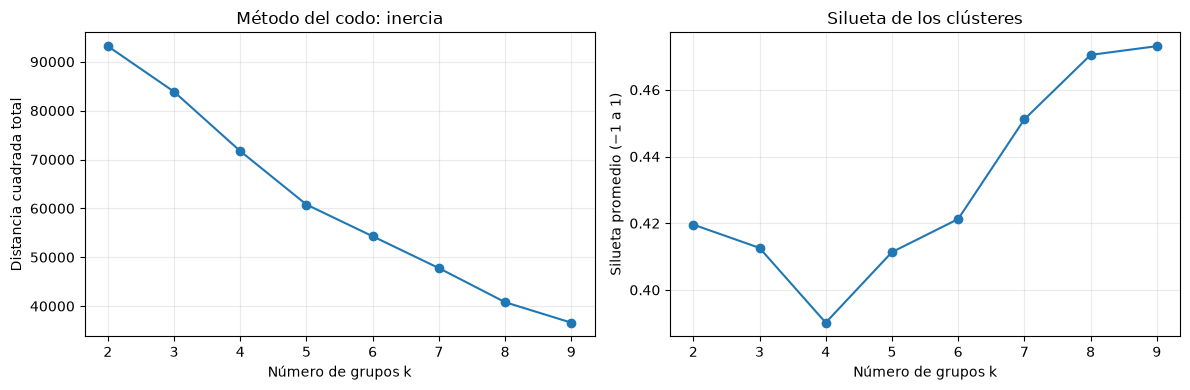

In [6]:
# A.3) Conservar k=2..9, cinco arranques y la misma muestra para silueta.
res = []
for k in range(2, 10):
    modelo = KMeans(n_clusters=k, n_init=5, random_state=0).fit(Xs)
    res.append({
        'k': k,
        'inercia': modelo.inertia_,
        'silueta': silhouette_score(
            Xs, modelo.labels_, sample_size=3000, random_state=0
        ),
        # Evaluación posterior: nunca se pasó 'category' a .fit().
        'ARI': adjusted_rand_score(sub['category'], modelo.labels_),
    })

r = pd.DataFrame(res).set_index('k')
print('=== A.3 · COMPARACIÓN DE NÚMERO DE CLÚSTERES ===')
display(r.rename(columns={
    'inercia': 'Inercia (menor, pero decrece con k)',
    'silueta': 'Silueta (mayor es mejor)',
    'ARI': 'ARI respecto a las familias reales',
}).round(3))

fig, ejes = plt.subplots(1, 2, figsize=(12, 4))
r['inercia'].plot(ax=ejes[0], marker='o')
ejes[0].set(title='Método del codo: inercia', xlabel='Número de grupos k',
            ylabel='Distancia cuadrada total', xticks=r.index)
r['silueta'].plot(ax=ejes[1], marker='o')
ejes[1].set(title='Silueta de los clústeres', xlabel='Número de grupos k',
            ylabel='Silueta promedio (−1 a 1)', xticks=r.index)
for eje in ejes:
    eje.grid(alpha=0.25)
fig.tight_layout()
plt.show()

**Cómo concluir:** observa dónde se suaviza la pendiente de **inercia** y dónde es mayor la **silueta**. Si discrepan, no hay un `k` universalmente correcto: la elección depende de cuánta granularidad necesite el analista. El ARI es una **comprobación externa** interesante porque tenemos etiquetas didácticas; no equivale a precisión, recall ni capacidad de detección de ataques. Los valores dependen del dataset y del preprocesamiento, así que no se fija un «mejor k» sin ver la tabla.

### A.4 · Reto avanzado original, resuelto: cuatro puntos y retirada del escalado

**Pregunta 1.** Comprueba a mano `1, 2, 10, 11`, con `k=2`: los dos centros son `1,5` y `10,5` y cada uno acumula `0,5` unidades de inercia; total **`J=1`**. Verificamos que la implementación encuentra ese resultado y, después, comparamos agrupaciones de NSL-KDD con y sin `StandardScaler`.

**Pregunta 2.** ¿«`src_bytes` decide solo los grupos» cuando quitamos el escalado? Lo correcto es comprobar las **contribuciones reales**: pueden dominar `src_bytes`, `dst_bytes`, `duration` u otras columnas de escala grande. Además, quitar solo `StandardScaler` **mantiene** `log1p`; quitar también `log1p` sería un experimento distinto. Calcularemos la inercia por variable después de `log1p` para ver cuál domina **esta muestra**.

In [7]:
# RETO A) Validación numérica simple: usar el algoritmo original sin modificarlo.
puntos = np.array([[1.0], [2.0], [10.0], [11.0]])
etiquetas_ejemplo, centros_ejemplo, inercia_ejemplo = kmeans(
    puntos, k=2, seed=0
)
centros_ordenados = np.sort(centros_ejemplo.ravel())
print('=== RETO A · COMPROBAR EL EJEMPLO DE CUATRO PUNTOS ===')
print('Puntos originales:', puntos.ravel().tolist())
print('Centros obtenidos (ordenados):', centros_ordenados.round(3).tolist())
print(f'Inercia J obtenida: {inercia_ejemplo:.3f} | Esperada: 1.000')

# Retirar SOLO StandardScaler: mantener log1p sobre las mismas 17 columnas.
X_sin_escalar = np.log1p(sub[num].to_numpy(dtype=float))
km_sin_escalar = KMeans(n_clusters=5, n_init=10, random_state=0).fit(X_sin_escalar)

# Cada diferencia al cuadrado suma una parte de la inercia total.
residuos = X_sin_escalar - km_sin_escalar.cluster_centers_[km_sin_escalar.labels_]
contribuciones = np.square(residuos).sum(axis=0)
contribuciones_pct = 100 * contribuciones / contribuciones.sum()

print('\n=== RETO A · SIN ESTANDARIZACIÓN (SE MANTIENE log1p) ===')
print('Inercia sin estandarización:', f'{km_sin_escalar.inertia_:,.1f}')
print('La inercia NO es comparable directamente con la de Xs: cambió la escala.')
print('Contribución porcentual a la inercia total por característica:')
display(pd.DataFrame({
    'Característica': num,
    '% de inercia': contribuciones_pct,
}).sort_values('% de inercia', ascending=False).head(10).round(2).reset_index(drop=True))

=== RETO A · COMPROBAR EL EJEMPLO DE CUATRO PUNTOS ===
Puntos originales: [1.0, 2.0, 10.0, 11.0]
Centros obtenidos (ordenados): [1.5, 10.5]
Inercia J obtenida: 1.000 | Esperada: 1.000

=== RETO A · SIN ESTANDARIZACIÓN (SE MANTIENE log1p) ===
Inercia sin estandarización: 66,181.6
La inercia NO es comparable directamente con la de Xs: cambió la escala.
Contribución porcentual a la inercia total por característica:


,Característica,% de inercia
0,src_bytes,27.89
1,dst_bytes,17.88
2,dst_host_count,14.27
3,count,11.73
4,dst_host_srv_count,11.29
5,srv_count,9.79
6,duration,3.40
7,hot,1.03
8,rerror_rate,0.55
9,serror_rate,0.45


**Respuesta razonada al reto:** en el ejemplo 1D, cualquier resultado con centros `1,5` y `10,5` tiene inercia `1`; los identificadores `0` y `1` de los grupos se pueden intercambiar. En NSL-KDD, una contribución porcentual elevada significa que esa columna aporta una gran parte de las diferencias cuadráticas **con estos clústeres**, no que cause los ataques. Si `src_bytes` no encabeza la tabla, se ha refutado para esta muestra la afirmación tajante del enunciado: quitar el escalado hace que **alguna combinación de variables de mayor dispersión** domine las distancias, no necesariamente una columna fija.

## Parte B · DBSCAN: clústeres por densidad y observaciones aisladas

**Objetivo:** detectar grupos con formas diversas sin indicarle de antemano cuántos grupos existen. A diferencia de k-means, **DBSCAN** no busca centros: comprueba si hay suficientes puntos dentro de una distancia pequeña. Las observaciones que no quedan asociadas a una zona densa se etiquetan `−1`, es decir, **ruido**.

Los dos parámetros que controlan el comportamiento son:

- **`eps`**: radio del vecindario. Con `eps=0,6`, dos conexiones tienen que estar mucho más próximas para pertenecer a una zona densa que con `eps=2,5` (las distancias se miden sobre los datos transformados).
- **`min_samples=10`**: tamaño mínimo del vecindario, incluyendo el propio punto, para que este pueda ser un **punto núcleo**. Los puntos próximos a un núcleo pueden quedar en el mismo grupo aunque ellos mismos no sean núcleo.

**¿Cómo elegimos `eps`?** Para cada conexión buscamos la distancia hasta su **10.º vecino** (contando el propio punto), las ordenamos y dibujamos la curva. Un cambio pronunciado de pendiente puede señalar dónde empiezan las observaciones poco densas. No siempre hay un codo claro.

**PCA antes de DBSCAN:** `Xs` contiene 17 características ya escaladas. Reducimos a `Z` con **8 componentes principales**: nuevas coordenadas que resumen las direcciones con mayor variabilidad. Al reducir dimensiones podemos disminuir ruido y hacer más manejable la búsqueda de vecinos; **a cambio perdemos información**, posiblemente útil para detectar ataques. `PCA` se ajusta sin las etiquetas y aquí se aplica sobre la misma muestra de entrenamiento.

**Importante:** la etiqueta `−1` significa **aislamiento geométrico**, no «ataque». Un ataque repetido miles de veces puede formar un clúster denso; una operación administrativa válida puede quedar aislada.

=== B.1 · CURVA PARA EXPLORAR eps ===
Dimensiones antes de PCA: 17
Dimensiones después de PCA: 8
Conexiones representadas en la curva: 8,000
La curva está ordenada de menor a mayor distancia al décimo vecino.


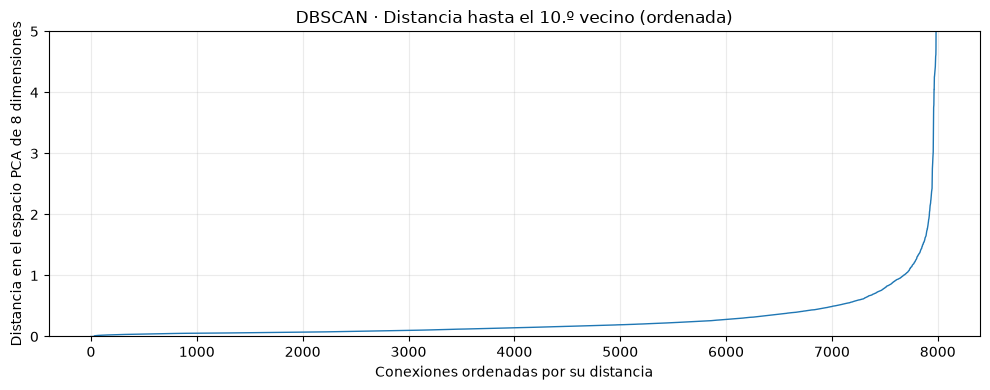


=== B.2 · EFECTO DE eps EN DBSCAN ===


,eps,Número de clústeres,Conexiones consideradas ruido,% de conexiones en ruido,% ataques dentro del ruido,% ataques fuera del ruido
0,0.6,17,520,6.50,29.62,47.81
1,1.2,12,128,1.60,30.47,46.89
2,2.5,3,44,0.55,34.09,46.69


Los porcentajes de ataques se obtienen consultando etiquetas DESPUÉS de ajustar DBSCAN.
Si un grupo está vacío, su porcentaje aparece como NaN (no es cero).


In [8]:
# B.1) Reducción de 17 características a 8 componentes para el clustering.
from sklearn.cluster import DBSCAN
from sklearn.neighbors import NearestNeighbors
from sklearn.decomposition import PCA

Z = PCA(n_components=8, random_state=0).fit_transform(Xs)

# kneighbors devuelve distancias ordenadas de menor a mayor para 10 vecinos.
# La última columna es la distancia al 10.º vecino.
dist, _ = NearestNeighbors(n_neighbors=10).fit(Z).kneighbors(Z)
distancia_decimo_vecino = np.sort(dist[:, -1])

print('=== B.1 · CURVA PARA EXPLORAR eps ===')
print(f'Dimensiones antes de PCA: {Xs.shape[1]}')
print(f'Dimensiones después de PCA: {Z.shape[1]}')
print(f'Conexiones representadas en la curva: {Z.shape[0]:,}')
print('La curva está ordenada de menor a mayor distancia al décimo vecino.')

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(distancia_decimo_vecino, lw=1)
ax.set_ylim(0, 5)  # Mismo límite original: valores por encima de 5 quedan fuera del gráfico.
ax.set(title='DBSCAN · Distancia hasta el 10.º vecino (ordenada)',
       xlabel='Conexiones ordenadas por su distancia',
       ylabel='Distancia en el espacio PCA de 8 dimensiones')
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

# B.2) Mantener EXACTAMENTE los tres radios y el mínimo de 10 puntos originales.
resultados_dbscan = []
for eps in [0.6, 1.2, 2.5]:
    db = DBSCAN(eps=eps, min_samples=10).fit(Z)
    ruido = db.labels_ == -1

    # Las etiquetas reales se consultan SOLO para medir qué hay en el ruido.
    # Una media sobre un grupo vacío devuelve NaN: representa 'no aplicable'.
    resultados_dbscan.append({
        'eps': eps,
        'Número de clústeres': int(db.labels_.max() + 1),
        'Conexiones consideradas ruido': int(ruido.sum()),
        '% de conexiones en ruido': 100 * ruido.mean(),
        '% ataques dentro del ruido': 100 * sub['is_attack'][ruido].mean(),
        '% ataques fuera del ruido': 100 * sub['is_attack'][~ruido].mean(),
    })

print('\n=== B.2 · EFECTO DE eps EN DBSCAN ===')
display(pd.DataFrame(resultados_dbscan).round(2))
print('Los porcentajes de ataques se obtienen consultando etiquetas DESPUÉS de ajustar DBSCAN.')
print('Si un grupo está vacío, su porcentaje aparece como NaN (no es cero).')

**Interpretación del gráfico y de la tabla:** cuando `eps` aumenta, normalmente disminuye la fracción de conexiones que queda aislada, porque más puntos se conectan entre sí; el número de clústeres puede **subir o bajar** al fusionarse regiones. La columna «% ataques dentro del ruido» es **precisión si interpretásemos todo el ruido como alerta**, no recall: para calcular recall habría que dividir los ataques en ruido entre **todos** los ataques de la muestra. Si hay `0` observaciones en ruido, no se puede calcular ese porcentaje.

El gráfico tiene el mismo límite vertical `0–5` que el original; puede ocultar distancias superiores. **Una línea que sale del gráfico no significa que esas distancias no existan.**

### Reto avanzado B · ¿Por qué reducir dimensiones antes de DBSCAN?

En muchas dimensiones, las distancias entre puntos tienden a concentrarse: puede costar distinguir un vecino verdaderamente cercano de otro lejano. Es parte de la llamada **maldición de la dimensionalidad**. Si 17 variables aportan pequeñas diferencias, su suma puede hacer que todas las conexiones parezcan separadas de forma parecida; el mismo `eps` deja de discriminar.

**PCA** concentra parte de la variabilidad en 8 coordenadas, facilitando el cálculo de vecinos y, en ocasiones, la separación de densidades. Sin embargo, la dirección en la que hay **menos** variación podría ser precisamente la que distingue un ataque sutil. Por eso **«menos dimensiones = mejor» no es una ley**. Comparamos, sin cambiar el algoritmo, la dispersión relativa de distancias en 17 y 8 dimensiones para observar el efecto en esta muestra.

In [9]:
# RETO B) Comparar qué tan concentradas están las distancias a vecinos.
# Coeficiente de variación = desviación típica / media.
# Valores más bajos significan distancias más similares entre sí.
vecinos_17, _ = NearestNeighbors(n_neighbors=10).fit(Xs).kneighbors(Xs)
vecinos_8, _ = NearestNeighbors(n_neighbors=10).fit(Z).kneighbors(Z)

comparacion_distancias = pd.DataFrame({
    'Espacio': ['Original escalado', 'PCA reducido'],
    'Dimensiones': [Xs.shape[1], Z.shape[1]],
    'Distancia media al 10.º vecino': [vecinos_17[:, -1].mean(),
                                      vecinos_8[:, -1].mean()],
    'Desviación de las distancias': [vecinos_17[:, -1].std(),
                                    vecinos_8[:, -1].std()],
    'Variación relativa (desv. / media)': [
        vecinos_17[:, -1].std() / vecinos_17[:, -1].mean(),
        vecinos_8[:, -1].std() / vecinos_8[:, -1].mean(),
    ],
})
print('=== RETO B · DISTANCIAS EN 17 Y 8 DIMENSIONES ===')
display(comparacion_distancias.round(3))
print('No compares las distancias absolutas como si ambas representaciones tuvieran la misma escala.')

=== RETO B · DISTANCIAS EN 17 Y 8 DIMENSIONES ===


,Espacio,Dimensiones,Distancia media al 10.º vecino,Desviación de las distancias,Variación relativa (desv. / media)
0,Original escalado,17,0.479,0.964,2.012
1,PCA reducido,8,0.286,0.855,2.988


No compares las distancias absolutas como si ambas representaciones tuvieran la misma escala.


**Respuesta:** si en la tabla la variación relativa crece tras PCA, las distancias de los vecinos se han hecho **más diferenciables en esta muestra**; si disminuye, no ocurrió así. Ninguna de las dos observaciones demuestra por sí sola que DBSCAN detecte mejor los ataques. Para afirmarlo habría que medir la calidad de los grupos y los ataques aislados, conservando un conjunto de evaluación independiente.

## Parte C · PCA como detector: reconstrucción de tráfico normal

**Objetivo:** entrenar con **conexiones normales** y asignar una puntuación de anomalía a cualquier conexión nueva. En esta parte, PCA ya no se usa para dibujar grupos: se usa para **aprender a reconstruir el tráfico que conoce**.

Supón que cada conexión tiene 17 números. PCA aprende un conjunto de ejes que resumen cómo varían las conexiones **normales**. Si retenemos `k=2` componentes, comprimimos cada fila de 17 números a 2 y, después, intentamos recuperar los 17 originales. Para una conexión habitual puede existir una aproximación razonable; para una conexión diferente, la reconstrucción puede fallar.

La puntuación es la suma de errores cuadrados de sus 17 características:

$$
\text{error de reconstrucción} = \sum_{j=1}^{17} (x_j - \widehat{x}_j)^2.
$$

Por ejemplo, si una conexión tiene características `[2, 5]` y PCA reconstruye `[2, 8]`, los errores son `0` y `−3`; la puntuación es `0² + (−3)² = 9`. **Cuanto mayor, más inusual** según el modelo. No es una probabilidad de ataque.

**Fuga de información:** el preprocesador `pre_n` se ajusta **solo con filas normales del entrenamiento** (`tr['is_attack'] == 0`); no se usa la distribución del test para calcular medias, desviaciones ni direcciones PCA. Las etiquetas de la prueba se consultan al calcular AUC/AP. Aquí necesitamos conocer qué filas de entrenamiento son normales: es un método **semisupervisado o de detección de novedades**, no un entrenamiento totalmente sin etiquetas.

**¿Qué significa `k` en PCA?** Número de componentes retenidos (no de clústeres). Con pocos componentes hay más compresión; con muchos, el modelo puede reconstruir también ataques. Pero la tendencia exacta depende de los datos: **hay que medirla**.

In [10]:
# C.1) Entrenar el preprocesador SOLO con ejemplos normales del entrenamiento.
from sklearn.metrics import roc_auc_score, average_precision_score
import time

normal = tr[tr['is_attack'] == 0]
pre_n = make_pipeline(FunctionTransformer(np.log1p), StandardScaler()).fit(normal[num])

Xn = pre_n.transform(normal[num])  # Conexiones normales de entrenamiento.
Xt = pre_n.transform(te[num])      # Conexiones de test: normales y ataques.

print('=== C.1 · PREPARACIÓN DE PCA COMO DETECTOR ===')
print(f'Entrenamiento normal: {Xn.shape[0]:,} filas × {Xn.shape[1]} características')
print(f'Prueba completa:       {Xt.shape[0]:,} filas × {Xt.shape[1]} características')

# explained_variance_ratio_: fracción de variación del normal capturada por cada eje.
pca_exploratoria = PCA().fit(Xn)
varianza_acumulada = np.cumsum(pca_exploratoria.explained_variance_ratio_)
print('\nVariación acumulada explicada por las componentes sucesivas:')
display(pd.DataFrame({
    'Componentes retenidas': np.arange(1, len(varianza_acumulada) + 1),
    '% de variación del normal explicada': 100 * varianza_acumulada,
}).round(2).set_index('Componentes retenidas'))

=== C.1 · PREPARACIÓN DE PCA COMO DETECTOR ===
Entrenamiento normal: 67,343 filas × 17 características
Prueba completa:       22,544 filas × 17 características

Variación acumulada explicada por las componentes sucesivas:


,% de variación del normal explicada
Componentes retenidas,
1,20.61
2,35.29
3,47.22
4,55.49
5,62.72
6,69.07
7,74.79
8,80.14
9,84.41


**Cómo interpretar la variación explicada:** si las primeras cuatro componentes reúnen, por ejemplo, el **85 %**, significa que capturan el 85 % de la variación total **del tráfico normal de entrenamiento**, no que detecten el 85 % de ataques ni que sean un 85 % «precisas». Un eje con poca varianza todavía puede ser importante para reconocer anomalías.

In [11]:
# C.2) Ajustar PCA con exactamente los k originales y evaluar SOLO en test.
resultados_pca = []
pca_reto = None  # Conservaremos k=8 para el experimento de umbral del reto.

for k in [2, 4, 6, 8, 12]:
    inicio = time.perf_counter()
    modelo_pca = PCA(n_components=k).fit(Xn)
    tiempo_ajuste = time.perf_counter() - inicio

    # Reducir 17 coordenadas a k y reconstruirlas en las 17 originales.
    reconstruccion_test = modelo_pca.inverse_transform(modelo_pca.transform(Xt))
    error_test = ((Xt - reconstruccion_test) ** 2).sum(axis=1)

    resultados_pca.append({
        'Componentes k': k,
        'ROC AUC': roc_auc_score(te['is_attack'], error_test),
        'AP': average_precision_score(te['is_attack'], error_test),
        'Tiempo de ajuste (s)': tiempo_ajuste,
    })
    if k == 8:
        pca_reto = modelo_pca
        puntuacion_pca_8 = error_test
        tiempo_pca_8 = tiempo_ajuste

print('=== C.2 · ERROR DE RECONSTRUCCIÓN COMO PUNTUACIÓN DE ANOMALÍA ===')
display(pd.DataFrame(resultados_pca).set_index('Componentes k').round(3))
print('ROC AUC/AP: más alto suele indicar mejor ORDENACIÓN de los ataques en test.')
print('El error de reconstrucción es mayor cuando PCA reconstruye peor una conexión.')

=== C.2 · ERROR DE RECONSTRUCCIÓN COMO PUNTUACIÓN DE ANOMALÍA ===


,ROC AUC,AP,Tiempo de ajuste (s)
Componentes k,,,
2,0.955,0.959,0.004
4,0.963,0.965,0.003
6,0.963,0.962,0.003
8,0.955,0.958,0.002
12,0.928,0.945,0.003


ROC AUC/AP: más alto suele indicar mejor ORDENACIÓN de los ataques en test.
El error de reconstrucción es mayor cuando PCA reconstruye peor una conexión.


**Interpretación:** compara las filas de `k=2`, `4`, `6`, `8` y `12` utilizando **ambas** métricas. El valor óptimo no tiene por qué ser el menor `k`: con demasiada compresión se puede perder el comportamiento normal; con muy poca compresión se pueden reconstruir también comportamientos anómalos. Si la AP baja mientras el AUC se mantiene, el detector puede conservar una buena ordenación global, pero ser menos útil al priorizar alertas cuando los ataques son minoritarios.

### Reto avanzado C · Umbral del percentil 99, recall y falsas alarmas

**Pregunta original:** fija un umbral en el percentil 99 del error de reconstrucción **sobre el tráfico normal de entrenamiento** y calcula recall y tasa de falsas alarmas en test.

Un **percentil 99** es el valor por debajo del cual está aproximadamente el 99 % de las puntuaciones de referencia: si 1.000 conexiones normales tienen errores ordenados, el umbral estará cerca del error de la conexión número 990. Marcamos como anomalía `puntuación > umbral`.

**Por qué aquí y no en test:** ajustar el umbral mirando los ataques de test daría una evaluación optimista. Al escogerlo con errores normales de entrenamiento, la futura evaluación sigue siendo independiente. La fracción de falsas alarmas sobre **datos normales de prueba** no tiene por qué ser exactamente 1 %: sus distribuciones pueden cambiar.

El reto no especificaba cuántas componentes usar; elegimos **`k=8`**, uno de los valores originales ya comparados, y explicamos esta decisión sin atribuírsela al enunciado.

In [12]:
# RETO C) Fijar el umbral sobre entrenamiento NORMAL, nunca sobre test.
reconstruccion_normal = pca_reto.inverse_transform(pca_reto.transform(Xn))
error_normal = ((Xn - reconstruccion_normal) ** 2).sum(axis=1)
umbral_pca_99 = np.quantile(error_normal, 0.99)

alerta_pca = puntuacion_pca_8 > umbral_pca_99
verdad_test = te['is_attack'].to_numpy(dtype=bool)

TP_pca = int(np.sum(alerta_pca & verdad_test))
FP_pca = int(np.sum(alerta_pca & ~verdad_test))
FN_pca = int(np.sum(~alerta_pca & verdad_test))
TN_pca = int(np.sum(~alerta_pca & ~verdad_test))
recall_pca = TP_pca / (TP_pca + FN_pca)
fpr_pca = FP_pca / (FP_pca + TN_pca)
precision_pca = TP_pca / (TP_pca + FP_pca) if TP_pca + FP_pca else float('nan')

print('=== RETO C · PCA CON k=8 Y UMBRAL DEL PERCENTIL 99 NORMAL ===')
print(f'Umbral obtenido del entrenamiento normal: {umbral_pca_99:,.3f}')
print('Una conexión de test genera alerta si su error de reconstrucción supera el umbral.')
display(pd.DataFrame({
    'Concepto': [
        'TP · Ataques detectados', 'FP · Normales alertados',
        'FN · Ataques no detectados', 'TN · Normales descartados',
    ],
    'Conexiones de test': [TP_pca, FP_pca, FN_pca, TN_pca],
}))
print(f'Recall de ataques en test:          {recall_pca:.1%} ({TP_pca}/{TP_pca + FN_pca})')
print(f'Tasa de falsas alarmas en test:   {fpr_pca:.1%} ({FP_pca}/{FP_pca + TN_pca})')
print(f'Precisión de las alertas en test: {precision_pca:.1%}')

=== RETO C · PCA CON k=8 Y UMBRAL DEL PERCENTIL 99 NORMAL ===
Umbral obtenido del entrenamiento normal: 34.087
Una conexión de test genera alerta si su error de reconstrucción supera el umbral.


,Concepto,Conexiones de test
0,TP · Ataques detectados,3232
1,FP · Normales alertados,26
2,FN · Ataques no detectados,9601
3,TN · Normales descartados,9685


Recall de ataques en test:          25.2% (3232/12833)
Tasa de falsas alarmas en test:   0.3% (26/9711)
Precisión de las alertas en test: 99.2%


**Respuesta:** el **recall** indica qué proporción de los ataques reales superan el umbral, y la **FPR** qué proporción de las conexiones normales lo supera por error. Son dos denominadores diferentes. Un umbral más alto generalmente reduce alertas y falsos positivos, **pero también puede dejar pasar ataques**. El 1 % del percentil es una referencia del entrenamiento normal, **no una garantía** sobre nuevas conexiones. El AUC/AP de la parte anterior resume el *ranking* sin fijar umbral; este reto evalúa **una política concreta de alertas**.

## Parte D · Tres detectores no supervisados: Isolation Forest, LOF y One-Class SVM

**Objetivo:** entrenar tres algoritmos con **las mismas 10.000 conexiones normales** (submuestra de las usadas en PCA) y comparar cómo ordenan los ejemplos del test. Los tres reciben los mismos **17 números previamente transformados con `pre_n`** (logaritmo + estandarización); ninguna etiqueta de ataque entra en `.fit()`.

**Cómo detecta cada uno:**

| Detector | Mecanismo intuitivo | Qué significa puntuación alta en este cuaderno |
|---|---|---|
| **Isolation Forest** | Crea árboles con cortes aleatorios. Los puntos aislados en pocas particiones suelen ser más raros. | Fácil de aislar respecto a las conexiones normales. |
| **LOF, modo *novelty*** | Compara la densidad local de una conexión con la de sus vecinas aprendidas en el entrenamiento. | La conexión es menos densa que su entorno de referencia. |
| **One-Class SVM** | Aprende una frontera flexible que rodea una región de datos normales; `nu` influye en el compromiso entre margen y observaciones fuera de esa región. | Queda más lejos del interior de la región que el modelo considera normal. |

**¿Por qué negamos `decision_function`?** Estos modelos suelen dar **puntuaciones más altas a lo normal**. Al multiplicarlas por `−1`, **más alto significa más sospechoso** para los tres, algo indispensable antes de comparar AUC y AP. Esa inversión no cambia qué observaciones son raras; solo fija una orientación coherente.

**Sobre `n_neighbors`, `nu` y `contamination`:** `n_neighbors=35` hace que LOF compare vecindarios locales de 35 observaciones. `nu=0,05` configura el modelo One-Class SVM, influyendo en la frontera. `contamination` de Isolation Forest (que probaremos en el reto) ajusta el **umbral de decisión** según la proporción supuesta de atípicos; con mismos datos y semilla, por sí solo **no aprende árboles diferentes**. El umbral de percentil 99 que usaremos para Isolation Forest se calculará explícitamente, con independencia de su umbral interno.

In [13]:
# D.1) Submuestra NORMAL de 10.000 puntos, idéntica a la del notebook original.
from sklearn.ensemble import IsolationForest
from sklearn.neighbors import LocalOutlierFactor
from sklearn.svm import OneClassSVM

Xn_s = Xn[np.random.default_rng(0).choice(len(Xn), 10000, replace=False)]

# Mantener hiperparámetros originales, tiempo de ajuste y evaluación en test.
filas = []
modelos_anomalia = {
    'Isolation Forest': IsolationForest(
        n_estimators=300, random_state=0, n_jobs=-1
    ),
    'LOF': LocalOutlierFactor(n_neighbors=35, novelty=True),
    'One-Class SVM': OneClassSVM(kernel='rbf', nu=0.05, gamma='scale'),
}

for nombre, modelo in modelos_anomalia.items():
    t0 = time.perf_counter()  # Reloj para medir la fase .fit (NO inferencia).
    modelo.fit(Xn_s)
    t1 = time.perf_counter()

    # -decision_function: más POSITIVO = más anómalo para los tres.
    puntuaciones = -modelo.decision_function(Xt)
    filas.append({
        'Detector': nombre,
        'ROC AUC': roc_auc_score(te['is_attack'], puntuaciones),
        'AP': average_precision_score(te['is_attack'], puntuaciones),
        'Tiempo de ajuste (s)': t1 - t0,
    })

    if nombre == 'Isolation Forest':
        iso, s_iso = modelo, puntuaciones

resultados_detectores = pd.DataFrame(filas)
print('=== D.1 · DETECTORES AJUSTADOS SOLO CON NORMAL ===')
display(resultados_detectores.round(3).set_index('Detector'))
print('AUC / AP evalúan el orden de conexiones anómalas frente a etiquetas REALES de test.')
print('Tiempo: solo entrenamiento (.fit); no incluye la transformación ni la inferencia.')

# Mantener score_iso en test para la parte G.
te['score_iso'] = s_iso

# Igual que en el original, el umbral se fija con el percentil 99 sobre
# las puntuaciones de la muestra NORMAL que se empleó para entrenar.
umbral = np.quantile(-iso.decision_function(Xn_s), 0.99)

print('\n=== D.2 · RECALL POR FAMILIA DE ATAQUE, CON UMBRAL P99 NORMAL ===')
print(f'Umbral de Isolation Forest: {umbral:.4f} (mayor puntuación = más anomalía)')
recall_por_categoria = (
    te.loc[te['is_attack'] == 1]
    .groupby('category')['score_iso']
    .apply(lambda x: (x > umbral).mean())
)
recuento_ataques_por_categoria = te.loc[te['is_attack'] == 1, 'category'].value_counts()
display(pd.DataFrame({
    'Ataques de test': recuento_ataques_por_categoria,
    'Recall (fracción detectada)': recall_por_categoria,
    'Recall (%)': 100 * recall_por_categoria,
}).round(2).rename_axis('Familia de ataque'))

# La FPR nos dice cuánto coste operativo causa el umbral en test.
normal_test = te['is_attack'].eq(0)
fpr_iso = (te.loc[normal_test, 'score_iso'] > umbral).mean()
print(f'Falsas alarmas (FPR) en las conexiones normales de test: {fpr_iso:.2%}')

=== D.1 · DETECTORES AJUSTADOS SOLO CON NORMAL ===


,ROC AUC,AP,Tiempo de ajuste (s)
Detector,,,
Isolation Forest,0.951,0.962,0.255
LOF,0.876,0.873,0.122
One-Class SVM,0.922,0.949,0.141


AUC / AP evalúan el orden de conexiones anómalas frente a etiquetas REALES de test.
Tiempo: solo entrenamiento (.fit); no incluye la transformación ni la inferencia.

=== D.2 · RECALL POR FAMILIA DE ATAQUE, CON UMBRAL P99 NORMAL ===
Umbral de Isolation Forest: 0.1185 (mayor puntuación = más anomalía)


,Ataques de test,Recall (fracción detectada),Recall (%)
Familia de ataque,,,
dos,7458,0.64,64.05
probe,2421,0.69,68.61
r2l,2887,0.01,0.69
u2r,67,0.12,11.94


Falsas alarmas (FPR) en las conexiones normales de test: 1.04%


**Cómo leer la tabla D.1:** AUC y AP altos indican mejor ordenación de los ataques **en este test concreto**; no prueban que el método vaya a funcionar igual en producción. Un tiempo de ajuste pequeño no implica que la predicción también sea rápida. Los tiempos dependen del equipo: compara tendencias, no trates los segundos como una propiedad fija del algoritmo.

**Cómo leer D.2:** un recall de `0,60` para `r2l` significa «60 de cada 100 ataques de esa familia se detectarían bajo este umbral», **si hubiera 100**; revisa la columna de número de ataques antes de sacar conclusiones. Los ataques DoS y probe pueden ser más fáciles de distinguir por volumen o patrones de red; ataques R2L y U2R pueden imitar acciones legítimas. **Es una hipótesis de dominio, no una garantía para todas las muestras**: usa los valores medidos.

El original menciona AUC «entre 0,87 y 0,95». Eso es una **expectativa orientativa**, no una comprobación ni un resultado fijo.

### Reto avanzado D · Ajustar `nu` y `contamination`, medir falsas alarmas y comparar con Random Forest

**Pregunta 1.** ¿Qué cambia cuando variamos `nu` del One-Class SVM y `contamination` del Isolation Forest? Para compararlos necesitamos fijar el significado de «alerta»: usaremos `modelo.predict(X) == −1`, donde `−1` indica anomalía y `+1` indica normal.

- En **Isolation Forest**, `contamination` cambia el punto de corte para considerar rara una conexión. Con los mismos árboles y semilla, cambiar ese parámetro no altera la **ordenación continua** de rareza ni AUC/AP, pero sí el **número de alertas**, FP y TP de la predicción binaria.
- En **One-Class SVM**, `nu` sí interviene en la optimización de la frontera, de forma que **pueden cambiar tanto el ranking como el umbral**. No debe interpretarse como «exactamente el `nu` por ciento de test serán anomalías».

**Pregunta 2.** ¿Cuánto perdemos frente al Random Forest de la sesión 5, que sí conoce etiquetas? Para tener una comparación **autónoma**, entrenaremos un **pequeño Random Forest supervisado nuevo**, sobre las mismas 17 características y sobre filas de entrenamiento, y evaluaremos todos los modelos en el **mismo test**. Este bosque es una **referencia adicional**, no una reconstrucción exacta del modelo ni de la validación de la sesión 5. La comparación muestra el efecto práctico de disponer de etiquetas, pero no aísla exclusivamente ese factor: también cambian los algoritmos y la cantidad/tipo de ejemplos usados.

In [14]:
# RETO D.1) Mismas entradas, distintos criterios de anomalía binaria.
resultados_umbral = []

for contaminacion in [0.01, 0.05, 0.15]:
    candidato = IsolationForest(
        n_estimators=300, random_state=0, n_jobs=-1,
        contamination=contaminacion
    ).fit(Xn_s)
    pred = candidato.predict(Xt) == -1
    resultados_umbral.append({
        'Detector': 'Isolation Forest', 'Parámetro': f'contamination={contaminacion}',
        'Alertas en test': int(pred.sum()),
        'Recall (ataques)': pred[verdad_test].mean(),
        'FPR (normales)': pred[~verdad_test].mean(),
    })

for nu_elegido in [0.01, 0.05, 0.15]:
    candidato = OneClassSVM(
        kernel='rbf', nu=nu_elegido, gamma='scale'
    ).fit(Xn_s)
    pred = candidato.predict(Xt) == -1
    resultados_umbral.append({
        'Detector': 'One-Class SVM', 'Parámetro': f'nu={nu_elegido}',
        'Alertas en test': int(pred.sum()),
        'Recall (ataques)': pred[verdad_test].mean(),
        'FPR (normales)': pred[~verdad_test].mean(),
    })

print('=== RETO D.1 · EFECTO DE CAMBIAR LOS HIPERPARÁMETROS ===')
display(pd.DataFrame(resultados_umbral).round(3).set_index(['Detector', 'Parámetro']))
print('Recall y FPR dependen de la decisión binaria .predict(), NO de AUC/AP.')

=== RETO D.1 · EFECTO DE CAMBIAR LOS HIPERPARÁMETROS ===


Alertas en test  Recall (ataques)  \
Detector         Parámetro                                               
Isolation Forest contamination=0.01             6567             0.504   
                 contamination=0.05             8829             0.666   
                 contamination=0.15            10393             0.772   
One-Class SVM    nu=0.01                       10337             0.758   
                 nu=0.05                       10985             0.796   
                 nu=0.15                       12253             0.864   

                                     FPR (normales)  
Detector         Parámetro                           
Isolation Forest contamination=0.01           0.010  
                 contamination=0.05           0.029  
                 contamination=0.15           0.050  
One-Class SVM    nu=0.01                      0.063  
                 nu=0.05                      0.079  
                 nu=0.15                      0.119

Recall y FPR dependen de la decisión binaria .predict(), NO de AUC/AP.


In [15]:
# RETO D.2) Referencia supervisada para comparar CON y SIN etiquetas de ataque.
from sklearn.ensemble import RandomForestClassifier

# Solo tr se usa para entrenar; las etiquetas de te siguen reservadas a evaluación.
# Aplicamos el mismo pre_n (ajustado sin test) para usar la misma representación.
Xtr_supervisado = pre_n.transform(tr[num])
rf_referencia = RandomForestClassifier(
    n_estimators=100, random_state=0, n_jobs=-1
)
inicio_rf = time.perf_counter()
rf_referencia.fit(Xtr_supervisado, tr['is_attack'])
tiempo_rf = time.perf_counter() - inicio_rf

# La probabilidad de clase 1 se usa SOLO como ranking, no como certeza de ataque.
probabilidad_rf = rf_referencia.predict_proba(Xt)[:, 1]
auc_rf = roc_auc_score(te['is_attack'], probabilidad_rf)
ap_rf = average_precision_score(te['is_attack'], probabilidad_rf)

comparacion_supervision = pd.concat([
    resultados_detectores[['Detector', 'ROC AUC', 'AP']],
    pd.DataFrame([{
        'Detector': 'Random Forest (supervisado, referencia)',
        'ROC AUC': auc_rf, 'AP': ap_rf,
    }]),
], ignore_index=True)

print('=== RETO D.2 · COMPARACIÓN SOBRE EL MISMO TEST DE NSL-KDD ===')
display(comparacion_supervision.round(3).set_index('Detector'))
print(f'Tiempo de entrenamiento del RF de referencia: {tiempo_rf:.2f} s')
print(f'Diferencia en AP (RF menos Isolation Forest): '
      f'{ap_rf - float(resultados_detectores.loc[resultados_detectores.Detector == "Isolation Forest", "AP"].iloc[0]):+.3f}')

=== RETO D.2 · COMPARACIÓN SOBRE EL MISMO TEST DE NSL-KDD ===


,ROC AUC,AP
Detector,,
Isolation Forest,0.951,0.962
LOF,0.876,0.873
One-Class SVM,0.922,0.949
"Random Forest (supervisado, referencia)",0.959,0.956


Tiempo de entrenamiento del RF de referencia: 0.68 s
Diferencia en AP (RF menos Isolation Forest): -0.005


**Respuesta razonada:** en la primera tabla, examina si aumentar `contamination` o `nu` aumenta el recall **a costa** de una FPR mayor. No presupongas que todo sube monótonamente, sobre todo en One-Class SVM. En la segunda, la diferencia de AP expresa **puntos de métrica** en el mismo conjunto de prueba, no «porcentaje de ataques perdido». Si Random Forest obtiene mejor AP, el resultado es compatible con la ventaja de conocer ejemplos de ataque, pero **no demuestra** que sea mejor en situaciones sin etiquetar, frente a ataques completamente nuevos o bajo deriva de datos. El entrenamiento supervisado no es directamente comparable a entrenar solo con normal: dispone de muestras de ataques y de más información sobre los datos.

## Parte E · Detectar comportamientos inusuales en `auth.log` sin etiquetas

**Objetivo:** analizar un registro de autenticación SSH y señalar ventanas con muchos intentos de inicio de sesión, errores o nombres de usuario distintos. No buscamos una vulnerabilidad concreta ni sabemos de antemano cuál es el «perfil normal» de cada IP.

`generar_authlog('auth.log', n_atacantes=12)` crea un **archivo sintético**, no un registro real capturado de una empresa. Incluye 40 IP legítimas y 12 IP que simulan ataques de fuerza bruta; los textos de dirección IP proceden de rangos reservados para este ejercicio. `auth_features` interpreta las líneas y agrupa por **IP y ventana de 10 minutos**. Cada **fila del resultado** es «una IP observada durante una ventana», **no una IP única ni una petición individual**.

Las columnas de entrada del modelo son:

- **`n`**: número de intentos de acceso en esa ventana.
- **`n_fail`**: intentos fallidos.
- **`n_users`**: nombres de usuario distintos probados.
- **`fail_ratio`**: fallidos divididos entre total de intentos; por ejemplo, `9/10 = 0,9`.

`IsolationForest(contamination=0.05)` ordena estos comportamientos sin consultar la columna `verdad`. En el archivo sintético, `verdad` se calcula a partir del prefijo de la IP del atacante y se usa **solo después**, como referencia para evaluar. En un registro real no tendríamos esa verdad fácilmente disponible.

**Precisión en los 20 primeros (`precision@20`):** de las 20 ventanas que consideramos más anómalas, ¿en cuántas aparece un atacante? Si 16 de las 20 tienen `verdad=1`, `precision@20 = 0,8`. **No quiere decir que se detectasen 16 IP diferentes**: una IP podría generar varias ventanas.

In [16]:
# E.1) Generar un registro SSH sintético (sobrescribe el mismo archivo en cada ejecución).
generar_authlog('auth.log', n_atacantes=12)
f = auth_features('auth.log')

# Ajustar Isolation Forest con cuatro características; 'verdad' NO entra.
cols = ['n', 'n_fail', 'n_users', 'fail_ratio']
iso_a = IsolationForest(
    n_estimators=200, contamination=0.05, random_state=0
).fit(f[cols])

# score_samples suele ser mayor en registros habituales; cambiar de signo
# permite ordenar de mayor a menor rareza, como hicimos en la parte D.
f['score'] = -iso_a.score_samples(f[cols])
top = f.sort_values('score', ascending=False).head(20)

print('=== E.1 · AUTH.LOG SINTÉTICO ===')
print(f'Intentos agrupados en {len(f)} ventanas (IP + períodos de 10 min).')
print(f'IP diferentes en el registro: {f["ip"].nunique()}')
print('Variables usadas para la detección:', ', '.join(cols))
print('\nLas 10 ventanas MÁS ANÓMALAS (de las 20 revisadas):')
display(top[['ip', 'win', 'n', 'n_fail', 'n_users',
             'fail_ratio', 'score', 'verdad']].head(10).rename(columns={
                 'ip': 'IP origen', 'win': 'Ventana de 10 min',
                 'n': 'Intentos', 'n_fail': 'Fallidos',
                 'n_users': 'Usuarios distintos',
                 'fail_ratio': 'Fracción fallida',
                 'score': 'Puntuación de anomalía',
                 'verdad': 'Atacante simulado (1=sí)',
             }).round(3).reset_index(drop=True))

print('\n=== E.1 · EVALUACIÓN POSTERIOR CON LA VERDAD SINTÉTICA ===')
print(f'Precision@20: {top["verdad"].mean():.1%} '
      f'({int(top["verdad"].sum())} ventanas maliciosas / {len(top)} revisadas)')
print(f'ROC AUC de todas las ventanas: {roc_auc_score(f["verdad"], f["score"]):.3f}')
print('Atención: aquí cada observación es una VENTANA, no una IP única.')

=== E.1 · AUTH.LOG SINTÉTICO ===
Intentos agrupados en 838 ventanas (IP + períodos de 10 min).
IP diferentes en el registro: 52
Variables usadas para la detección: n, n_fail, n_users, fail_ratio

Las 10 ventanas MÁS ANÓMALAS (de las 20 revisadas):


/tmp/ipykernel_248175/3780747058.py:29: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  }).round(3).reset_index(drop=True))


,IP origen,Ventana de 10 min,Intentos,Fallidos,Usuarios distintos,Fracción fallida,Puntuación de anomalía,Atacante simulado (1=sí)
0,203.0.113.31,2026-10-01 06:10:00,140,140,10,1.0,0.784,1
1,203.0.113.21,2026-10-07 12:40:00,138,138,10,1.0,0.781,1
2,203.0.113.28,2026-10-01 22:10:00,122,122,10,1.0,0.747,1
3,203.0.113.31,2026-10-01 06:20:00,121,121,10,1.0,0.743,1
4,203.0.113.21,2026-10-07 12:30:00,119,119,10,1.0,0.738,1
5,203.0.113.20,2026-10-03 17:50:00,116,116,10,1.0,0.733,1
6,10.10.10.15,2026-10-01 17:40:00,2,0,2,0.0,0.731,0
7,10.10.10.17,2026-10-06 14:30:00,2,0,2,0.0,0.731,0
8,10.10.10.20,2026-10-01 08:10:00,2,0,2,0.0,0.731,0
9,10.10.10.22,2026-10-01 00:10:00,2,0,2,0.0,0.731,0



=== E.1 · EVALUACIÓN POSTERIOR CON LA VERDAD SINTÉTICA ===
Precision@20: 60.0% (12 ventanas maliciosas / 20 revisadas)
ROC AUC de todas las ventanas: 0.991
Atención: aquí cada observación es una VENTANA, no una IP única.


**Interpretación:** las primeras ventanas de la tabla acumulan el comportamiento más excepcional según cuatro contadores. Pueden corresponder a fuerza bruta, errores de configuración, automatización legítima o actividad administrativa inusual. `ROC AUC` usa la **verdad sintética** para medir el orden del detector, pero un analista real necesitaría evidencias adicionales. Además, una misma IP puede aparecer repetida y consumir varias posiciones del top 20: eso influye en la utilidad operacional de `precision@20`.

### Reto avanzado E · Solo dos atacantes y un administrador que se equivoca 20 veces

**Preguntas originales:** ¿qué ocurre si solo hay **2 IP atacantes** en vez de 12? ¿Y si un administrador legítimo falla 20 veces su contraseña? ¿Por qué sigue siendo una anomalía sin ser malicioso? ¿Qué contexto permite distinguirlo?

Si el ataque constituye un porcentaje pequeño del registro, las observaciones más raras **no tienen por qué ser ataques**. Una IP administrativa que falla 20 veces en 10 minutos comparte rasgos estadísticos con un intento automatizado de fuerza bruta. La puntuación no contiene intención, permisos ni conocimiento sobre trabajos autorizados.

Para comprobarlo sin tocar el `auth.log` del experimento anterior, generaremos **otro archivo** con 2 atacantes y añadiremos **20 fallos de un administrador legítimo simulado**. Esto es una **ampliación didáctica del reto**, no una modificación de cómo se generan los datos de la parte E original.

In [17]:
# RETO E) Nuevo escenario aislado: 2 IP atacantes y 20 errores de un administrador.
log_reto = 'auth_reto_dos_atacantes.log'
generar_authlog(log_reto, n_atacantes=2)

# Crear 20 líneas que la función auth_features del curso pueda interpretar:
# todas corresponden al MISMO usuario, IP legítima y ventana de 10 min.
ip_admin = '10.10.10.250'
with open(log_reto, 'a', encoding='utf-8') as archivo:
    for segundo in range(20):
        archivo.write(
            f'Oct 01 12:00:{segundo:02d} srv sshd[1234]: '
            f'Failed password for admin from {ip_admin} port 2222 ssh2\n'
        )

f_reto = auth_features(log_reto)
modelo_auth_reto = IsolationForest(
    n_estimators=200, contamination=0.05, random_state=0
).fit(f_reto[cols])
f_reto['score'] = -modelo_auth_reto.score_samples(f_reto[cols])
f_reto = f_reto.sort_values('score', ascending=False).reset_index(drop=True)
f_reto['Posición de anomalía'] = np.arange(1, len(f_reto) + 1)

filas_admin = f_reto.loc[f_reto['ip'] == ip_admin]
primeras_20_reto = f_reto.head(20)

print('=== RETO E · ESCENARIO CON DOS ATACANTES Y UN ADMINISTRADOR LEGÍTIMO ===')
print(f'Ventanas agregadas: {len(f_reto)} | IP atacantes simuladas: 2')
print(f'Atacantes en las 20 ventanas más anómalas: '
      f'{int(primeras_20_reto["verdad"].sum())}/{len(primeras_20_reto)}')
print(f'Precision@20: {primeras_20_reto["verdad"].mean():.1%}')
print('\nVentana del administrador legítimo (20 contraseñas fallidas):')
display(filas_admin[[
    'ip', 'win', 'n', 'n_fail', 'n_users', 'fail_ratio',
    'score', 'verdad', 'Posición de anomalía'
]].round(3))

print('\nDiez ventanas más anómalas del nuevo escenario:')
display(f_reto[['ip', 'n', 'n_fail', 'n_users', 'score', 'verdad']]
        .head(10).round(3))

=== RETO E · ESCENARIO CON DOS ATACANTES Y UN ADMINISTRADOR LEGÍTIMO ===
Ventanas agregadas: 800 | IP atacantes simuladas: 2
Atacantes en las 20 ventanas más anómalas: 8/20
Precision@20: 40.0%

Ventana del administrador legítimo (20 contraseñas fallidas):


/tmp/ipykernel_248175/1430065566.py:35: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  ]].round(3))


,ip,win,n,n_fail,n_users,fail_ratio,score,verdad,Posición de anomalía
14,10.10.10.250,2026-10-01 12:00:00,20,20,1,1.0,0.756,0,15



Diez ventanas más anómalas del nuevo escenario:


,ip,n,n_fail,n_users,score,verdad
0,203.0.113.21,138,138,10,0.857,1
1,203.0.113.21,119,119,10,0.850,1
2,203.0.113.21,114,114,10,0.850,1
3,203.0.113.20,116,116,10,0.848,1
4,203.0.113.20,91,91,10,0.842,1
5,203.0.113.20,95,95,10,0.842,1
6,203.0.113.20,18,18,7,0.809,1
7,203.0.113.21,8,8,5,0.762,1
8,10.10.10.34,2,0,2,0.759,0
9,10.10.10.15,2,0,2,0.759,0


**Respuesta al reto:** el administrador puede obtener una puntuación alta aun siendo `verdad=0`: es un **falso positivo operacional** si llegara a alertarse. No hay forma de concluir intención maliciosa a partir del número de fallos, y su **posición exacta** dependerá del resto de ventanas. Para desambiguar habría que comprobar: si la IP pertenece a un puesto gestionado o una VPN conocida, si existe una solicitud de soporte o cambio de credenciales, si el comportamiento coincide con una sesión administrativa aprobada, si finalmente hay un acceso correcto, si la MFA registra intentos anómalos y qué actividades ocurren después. Ninguna señal aislada autoriza a descartar automáticamente un incidente: por ejemplo, una cuenta administrativa puede ser utilizada por un atacante desde una IP interna comprometida.

## Parte F · Anomalías en una serie de DNS: z clásico frente a z robusto

**Objetivo:** estudiar un día de **1.440 minutos** en el que el tráfico DNS habitual tiene un promedio de unas **40 consultas por minuto**. Entre los minutos `800` y `919` (120 minutos = **dos horas**) agregamos aproximadamente **40 consultas por minuto** como simulación de exfiltración lenta. Es tráfico **artificial y etiquetado por construcción**, no una muestra de un ataque capturado.

**Problema estadístico:** si los valores sospechosos se incluyen al calcular la **media** y la **desviación típica**, elevan ambas. El umbral crece y puede dejar de marcar los minutos alterados. Esto se denomina aquí «contaminación» del valor de referencia.

**z clásico:**
$$
z = \frac{x-\text{media}}{\text{desviación típica}}.
$$
Un z de `3` significa que el punto está tres desviaciones típicas por encima de la media. Se marca si `|z| > 3`. Ejemplo: si media `40`, desviación `5` y valor `60`, entonces `z=(60−40)/5=4` y se detectaría.

**z robusto:** sustituimos la media por la **mediana** (valor central al ordenar) y la desviación típica por la **MAD** (*mediana de desviaciones absolutas respecto a la mediana*):
$$
\mathrm{MAD} = \mathrm{mediana}(|x_i-\mathrm{mediana}(x)|),\qquad
z_r=0{,}6745\,\frac{x-\mathrm{mediana}(x)}{\mathrm{MAD}}.
$$
`0,6745` aproxima la escala de una desviación típica cuando los datos se distribuyen de forma normal; se usa `|z_r| > 3,5` en el ejercicio. **Los umbrales 3 y 3,5 son elecciones de este laboratorio**, no reglas universales válidas para toda red.

**Diferencia importante:** la mediana resiste mejor unos pocos valores extremos; tampoco es inmune si la mayor parte de los datos cambia. Si `MAD=0`, el cálculo necesita una política alternativa para evitar dividir por cero. Aquí la variabilidad Poisson de la simulación hace que sea distinta de cero con esta semilla.

=== F.1 · SERIE DNS SINTÉTICA (CONSULTAS POR MINUTO) ===
Observaciones: 1,440 minutos (24 horas)
Intervalo modificado: minutos 800–919, ambos incluidos (120 min)
Media del día: 43.32 consultas/minuto
Desviación típica del día: 13.00 consultas/minuto
Mediana del día: 40.00 consultas/minuto
MAD del día: 5.00 consultas/minuto

=== F.2 · COMPARACIÓN DE ALERTAS Y DETECCIÓN ===


,Minutos marcados (total),Minutos de ataque detectados,Minutos normales marcados,Recall del episodio (%),FPR (% de minutos normales)
Detector,,,,,
z clásico: |z| > 3,52,52,0,43.33,0.00
"z robusto: |zᵣ| > 3,5",116,115,1,95.83,0.08


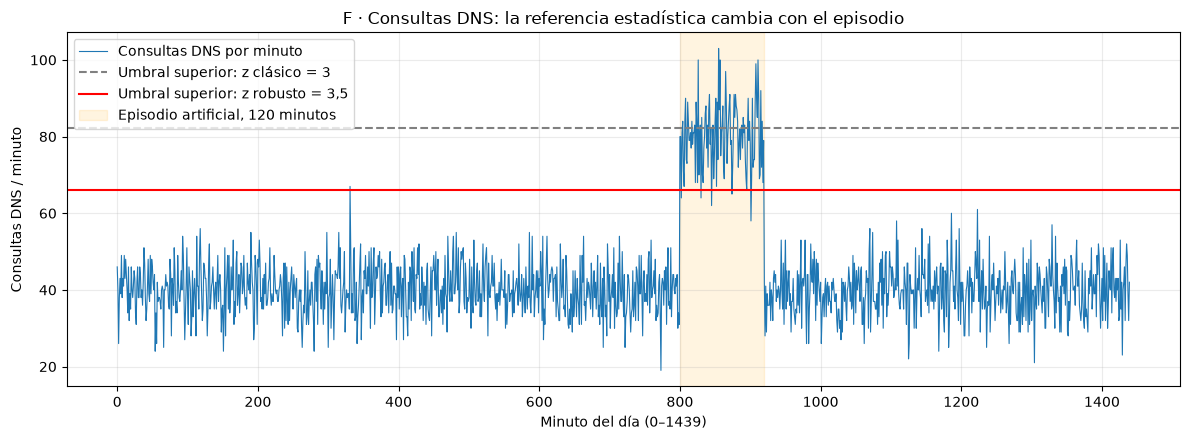

In [18]:
# F.1) Serie temporal reproducible: semilla original y 1.440 minutos.
rng = np.random.default_rng(5)
q = rng.poisson(40, 1440).astype(float)

# Los 120 minutos [800, 920) incluyen una segunda fuente de consultas
# con media de 40. NO sustituimos el tráfico normal: lo incrementamos.
q[800:920] += rng.poisson(40, 120)

# Ambas estadísticas se calculan sobre TODO el día, incluido el ataque.
z = (q - q.mean()) / q.std()
med = np.median(q)
mad = np.median(np.abs(q - med))
zr = 0.6745 * (q - med) / mad

# Detectores originales: extremos por arriba Y por abajo (valor absoluto).
alerta_clasica = np.abs(z) > 3
alerta_robusta = np.abs(zr) > 3.5

# Conocemos el episodio porque lo hemos creado; esto es evaluación, no ajuste.
minuto_ataque = np.zeros(len(q), dtype=bool)
minuto_ataque[800:920] = True

print('=== F.1 · SERIE DNS SINTÉTICA (CONSULTAS POR MINUTO) ===')
print(f'Observaciones: {len(q):,} minutos (24 horas)')
print('Intervalo modificado: minutos 800–919, ambos incluidos (120 min)')
print(f'Media del día: {q.mean():.2f} consultas/minuto')
print(f'Desviación típica del día: {q.std():.2f} consultas/minuto')
print(f'Mediana del día: {med:.2f} consultas/minuto')
print(f'MAD del día: {mad:.2f} consultas/minuto')

resumen_dns = []
for nombre, alerta in [
    ('z clásico: |z| > 3', alerta_clasica),
    ('z robusto: |zᵣ| > 3,5', alerta_robusta),
]:
    marcados_ataque = int(np.sum(alerta & minuto_ataque))
    falsas_alarmas = int(np.sum(alerta & ~minuto_ataque))
    resumen_dns.append({
        'Detector': nombre,
        'Minutos marcados (total)': int(alerta.sum()),
        'Minutos de ataque detectados': marcados_ataque,
        'Minutos normales marcados': falsas_alarmas,
        'Recall del episodio (%)': 100 * marcados_ataque / minuto_ataque.sum(),
        'FPR (% de minutos normales)': 100 * falsas_alarmas / (~minuto_ataque).sum(),
    })

print('\n=== F.2 · COMPARACIÓN DE ALERTAS Y DETECCIÓN ===')
display(pd.DataFrame(resumen_dns).round(2).set_index('Detector'))

# El gráfico conserva los mismos dos límites superiores del original,
# pero señala visualmente la ventana alterada y añade ejes/unidades.
fig, ax = plt.subplots(figsize=(12, 4.5))
ax.plot(np.arange(len(q)), q, lw=0.8, label='Consultas DNS por minuto')
ax.axhline(q.mean() + 3 * q.std(), color='gray', linestyle='--',
           label='Umbral superior: z clásico = 3')
ax.axhline(med + 3.5 * mad / 0.6745, color='red',
           label='Umbral superior: z robusto = 3,5')
ax.axvspan(800, 919, color='orange', alpha=0.12,
           label='Episodio artificial, 120 minutos')
ax.set(title='F · Consultas DNS: la referencia estadística cambia con el episodio',
       xlabel='Minuto del día (0–1439)', ylabel='Consultas DNS / minuto')
ax.legend(loc='upper left')
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

**Interpretación del gráfico:** la curva muestra consultas por minuto, la franja sombreada indica las dos horas alteradas y las líneas horizontales representan los **umbrales superiores**. Para el conteo se han utilizado `abs(z)` y `abs(zr)`, por lo que también se detectan extremos **inferiores**, aunque las líneas inferiores no se han dibujado para mantener legible el gráfico. La tabla distingue cuántos de los **120 minutos del episodio** se marcaron de cuántos minutos normales produjeron alertas. El texto original sugería que el z clásico marcaría menos de la mitad y el robusto casi todos: **compruébalo en la tabla**, porque esas afirmaciones dependen de la simulación y sus parámetros.

**Lo que no demuestra esta simulación:** que un aumento del número de consultas sea necesariamente una exfiltración. DNS también se dispara durante despliegues, resoluciones fallidas, actualizaciones, cambios de configuración o peticiones automatizadas legítimas. Tampoco demuestra que un túnel DNS real tenga que incrementar mucho la frecuencia; podría mantenerse dentro de un rango habitual.

### Reto avanzado F · Relación con un túnel DNS y regla equivalente de SIEM

Herramientas como **iodine** o **dnscat2** pueden transportar información encapsulada en consultas/respuestas DNS. El número de consultas puede aumentar, pero no es una firma exclusiva ni necesaria. Para verificar un túnel en tráfico real también serían útiles: longitud y entropía de subdominios, concentración en un dominio, destinos nuevos, porcentaje NXDOMAIN, longitud de respuestas, periodicidad, tipo de consulta y correlación con equipos/procesos.

**Regla conceptual del SIEM (agnóstica de producto):**

```text
Cada minuto, para cada IP_origen o equipo:
    consultas_actuales = número de consultas DNS durante este minuto
    referencia = historial válido de ese mismo equipo
                 (por ejemplo, 24 horas anteriores, excluyendo el minuto actual)
    mediana = mediana de consultas/minuto en la referencia
    MAD = mediana(|consultas_históricas - mediana|)

    si hay suficiente historial y MAD > 0:
        z_robusto = 0.6745 * (consultas_actuales - mediana) / MAD
        si z_robusto > 3.5:
            generar alerta con IP, dominio(s), z, volumen e historial
    si MAD == 0:
        aplicar una regla alternativa documentada (por ejemplo, umbral absoluto
        mínimo + multiplicador de la mediana), sin dividir entre cero
```

**Parámetros del reto:** agrupación **por equipo y minuto**, comparación contra una **línea base histórica** y umbral `3,5` como punto de partida. Esto difiere intencionadamente de la celda F, que utiliza el **día completo**, incluidos los minutos simulados. En un SIEM real conviene evitar que el minuto actual altere su propia referencia y separar horarios de trabajo de horas de baja actividad; también se necesita deduplicar alertas para que 120 minutos anómalos no generen 120 incidencias independientes.

**Ejemplo numérico:** con mediana `40` y MAD `5`, el umbral superior equivale a `40 + 3,5·5/0,6745 ≈ 65,9` consultas/minuto. Un minuto con 80 consultas lo supera. Si otro equipo siempre hace 200, debe tener **su propia** referencia y no ser sancionado solo por ser un equipo más activo.

In [19]:
# RETO F) Mostrar el umbral numérico y analizar un minuto concreto.
umbral_dns_robusto_superior = med + 3.5 * mad / 0.6745
umbral_dns_clasico_superior = q.mean() + 3 * q.std()
minuto_ilustrativo = 850  # Pertenece a [800, 920), el episodio simulado.

print('=== RETO F · LECTURA DE UNA REGLA DE ALERTA DNS ===')
print(f'Umbral superior z clásico: {umbral_dns_clasico_superior:.1f} consultas/min')
print(f'Umbral superior z robusto: {umbral_dns_robusto_superior:.1f} consultas/min')
print(f'Minuto {minuto_ilustrativo}: {q[minuto_ilustrativo]:.0f} consultas/min')
print(f'z clásico de ese minuto: {z[minuto_ilustrativo]:+.2f}')
print(f'z robusto de ese minuto: {zr[minuto_ilustrativo]:+.2f}')
print('¿Alerta clásica?:', 'sí' if alerta_clasica[minuto_ilustrativo] else 'no')
print('¿Alerta robusta?:', 'sí' if alerta_robusta[minuto_ilustrativo] else 'no')

=== RETO F · LECTURA DE UNA REGLA DE ALERTA DNS ===
Umbral superior z clásico: 82.3 consultas/min
Umbral superior z robusto: 65.9 consultas/min
Minuto 850: 84 consultas/min
z clásico de ese minuto: +3.13
z robusto de ese minuto: +5.94
¿Alerta clásica?: sí
¿Alerta robusta?: sí


**Respuesta al reto:** en el ejemplo de laboratorio, el z robusto suele mantener un umbral más estable porque dos horas de actividad incrementada son una minoría del día. La regla de SIEM traslada la idea a una comparación repetible por equipo, pero exige suficiente historial, mantenimiento de la línea base, control de horarios y validación con incidentes reales antes de usarla para generar respuestas automáticas.

## Parte G · Priorizar un presupuesto limitado de alertas

**Objetivo:** un centro de operaciones de seguridad (SOC) no puede investigar todo. Supón que el analista solo revisa las **100 conexiones más sospechosas** según Isolation Forest de la parte D. ¿Qué porcentaje serán ataques? ¿Y qué proporción de **todos los ataques** presentes en test estará cubierta por esas 100 revisiones?

Ordenamos las conexiones **de mayor a menor** puntuación `score_iso` (`−decision_function`, obtenida sin usar etiquetas). Después sí miramos `is_attack`, la etiqueta de evaluación del dataset.

- **`precision@k`**: número de ataques en las `k` conexiones más sospechosas, dividido entre `k` conexiones revisadas. Ejemplo: 70 ataques entre las 100 primeras -> `precision@100 = 70 %`.
- **Cobertura de ataques del test (`recall@k`)**: ataques presentes en las primeras `k`, divididos entre **todos** los ataques del conjunto de test. Ejemplo: 70 detectados entre 2.000 ataques totales -> `recall@100 = 3,5 %`.

**No confundas las dos medidas:** una precisión alta significa poco trabajo desperdiciado; una cobertura alta significa que casi no se dejan ataques sin revisar. Pueden entrar en conflicto cuando el presupuesto es pequeño.

El original comprueba `k = 50, 100, 500, 1.000, 5.000`; conservamos los cinco cortes. Añadimos una columna de **número real de conexiones revisadas** porque, si el test fuese más pequeño que `k`, `.head(k)` devolvería menos de `k` filas.

In [20]:
# G.1) Ordenar por la puntuación NO SUPERVISADA de Isolation Forest.
orden = te.sort_values('score_iso', ascending=False)
ataques_totales = int(te['is_attack'].sum())

resultados_presupuesto = []
for k in [50, 100, 500, 1000, 5000]:
    primeras = orden.head(k)  # No presupone que el test contenga >= k filas.
    ataques_revisados = int(primeras['is_attack'].sum())

    resultados_presupuesto.append({
        'Presupuesto k': k,
        'Conexiones realmente revisadas': len(primeras),
        'Ataques entre las revisadas': ataques_revisados,
        'Precision@k': primeras['is_attack'].mean(),
        'Cobertura de ataques del test': ataques_revisados / ataques_totales,
    })

print('=== G.1 · PRESUPUESTO DE ALERTAS (ISOLATION FOREST) ===')
print(f'Conexiones totales del test: {len(te):,}')
print(f'Ataques totales del test: {ataques_totales:,}')
display(pd.DataFrame(resultados_presupuesto).round(3).set_index('Presupuesto k'))
print('Precision@k = ataques revisados / conexiones revisadas.')
print('Cobertura = ataques revisados / TODOS los ataques presentes en test.')

=== G.1 · PRESUPUESTO DE ALERTAS (ISOLATION FOREST) ===
Conexiones totales del test: 22,544
Ataques totales del test: 12,833


,Conexiones realmente revisadas,Ataques entre las revisadas,Precision@k,Cobertura de ataques del test
Presupuesto k,,,,
50,50,50,1.000,0.004
100,100,100,1.000,0.008
500,500,500,1.000,0.039
1000,1000,1000,1.000,0.078
5000,5000,4985,0.997,0.388


Precision@k = ataques revisados / conexiones revisadas.
Cobertura = ataques revisados / TODOS los ataques presentes en test.


**Cómo interpretar la tabla:** revisa primero `precision@100` y compárala con la **prevalencia de ataques** en test (ataques totales / conexiones totales): esa prevalencia sería aproximadamente la precisión esperada al elegir filas **aleatoriamente**. Si el ranking sitúa muchos ataques en las primeras posiciones, priorizar ayuda al SOC. Sin embargo, incluso con precisión excelente, la cobertura puede ser pequeña cuando hay miles de ataques. Y una alta cobertura puede exigir revisar tantísimas conexiones que el volumen de falsos positivos resulte insostenible.

### Reto avanzado G · Simular la revisión humana y volver a ordenar el resto

**Problema original:** de las **100 primeras alertas** del detector, el analista revisa y asigna la etiqueta verdadera; con **solo esas 100 etiquetas**, entrena un `RandomForestClassifier` pequeño que puntúe el resto. ¿Mejora `precision@100` en **la siguiente tanda**?

Procedimiento reproducible y **sin fuga de etiquetas**:

1. Isolation Forest propone las primeras 100 alertas basándose en `score_iso` (aprendido con normales de entrenamiento).
2. Solo ahora, el analista «revela» las **etiquetas reales de esas 100 filas**. Las etiquetas de las filas pendientes **no** se entregan al Random Forest.
3. Entrenamos un bosque **con las mismas 17 características** y esas 100 etiquetas; el preprocesamiento `pre_n` se ajustó con entrenamiento, no con los datos de prueba.
4. Excluimos de los pendientes las primeras 100 ya revisadas. En las **siguientes 100** comparamos la selección por el ranking original de Isolation Forest con la selección por la probabilidad del nuevo Random Forest. Ambas compiten sobre **el mismo conjunto de filas pendientes**.
5. Consultamos sus etiquetas únicamente al calcular la **precision@100**, que simula el resultado de una evaluación posterior al trabajo del analista.

**Advertencia clave:** seleccionar para etiquetar solo el top 100 crea **sesgo de selección**: son ejemplos muy inusuales, nada representativos del conjunto. Además, si todas las primeras 100 conexiones tienen la misma etiqueta, el bosque solo aprende **una clase**, así que no puede ordenar por probabilidad de ataque de forma informativa. El código contempla ese caso y lo indica. **Este ejercicio simula un bucle humano, pero no prueba que el sistema mejore por sí solo en producción.**

In [21]:
# RETO G) Simular aprendizaje con el feedback de las primeras 100 alertas.
revisadas = orden.head(100).copy()
pendientes = orden.iloc[100:].copy()  # Evitar revisar dos veces la misma fila.

# Usar las mismas características numéricas y el preprocesador entrenado antes.
X_revisadas = pre_n.transform(revisadas[num])
X_pendientes = pre_n.transform(pendientes[num])
y_revisadas = revisadas['is_attack']  # ÚNICAS etiquetas entregadas al bosque.

rf_feedback = RandomForestClassifier(
    n_estimators=100, max_depth=5, random_state=0, n_jobs=-1
)
rf_feedback.fit(X_revisadas, y_revisadas)

if len(rf_feedback.classes_) == 1:
    # Evitar predict_proba[:,1] si el conjunto etiquetado tiene una sola clase.
    # La probabilidad de ataque es constante: no existe ranking supervisado útil.
    puntuacion_feedback = np.full(len(pendientes), float(rf_feedback.classes_[0]))
    ranking_aprendido = False
else:
    posicion_clase_ataque = list(rf_feedback.classes_).index(1)
    puntuacion_feedback = rf_feedback.predict_proba(X_pendientes)[:, posicion_clase_ataque]
    ranking_aprendido = True

pendientes['score_rf_feedback'] = puntuacion_feedback

# Mismo pool de candidatos pendientes, dos maneras de elegir los próximos 100.
siguiente_por_iso = pendientes.head(100)
siguiente_por_feedback = pendientes.sort_values(
    'score_rf_feedback', ascending=False, kind='stable'
).head(100)

precision_iso_siguiente = siguiente_por_iso['is_attack'].mean()
precision_feedback_siguiente = siguiente_por_feedback['is_attack'].mean()

print('=== RETO G · ANALISTA + NUEVO CLASIFICADOR (SOLO 100 ETIQUETAS) ===')
print(f'Conexiones etiquetadas manualmente: {len(revisadas)}')
print('Distribución de esas 100 etiquetas:')
display(y_revisadas.value_counts().rename(index={0: 'Normales', 1: 'Ataques'})
        .rename('Conexiones revisadas').to_frame())
print(f'Candidatos que quedan sin revisar: {len(pendientes):,}')
if not ranking_aprendido:
    print('AVISO: 100 etiquetas de una sola clase; el RF no puede aprender una distinción binaria.')

print('\n=== SEGUNDA TANDA · PRECISION@100 ===')
display(pd.DataFrame({
    'Forma de elegir las siguientes 100': [
        'Isolation Forest original', 'Random Forest con feedback',
    ],
    'Conexiones revisadas': [len(siguiente_por_iso), len(siguiente_por_feedback)],
    'Ataques encontrados': [
        int(siguiente_por_iso['is_attack'].sum()),
        int(siguiente_por_feedback['is_attack'].sum()),
    ],
    'Precision@100': [precision_iso_siguiente, precision_feedback_siguiente],
}).set_index('Forma de elegir las siguientes 100').round(3))
print(f'Diferencia RF − Isolation Forest: '
      f'{precision_feedback_siguiente - precision_iso_siguiente:+.3f} puntos de precisión (escala 0 a 1)')

=== RETO G · ANALISTA + NUEVO CLASIFICADOR (SOLO 100 ETIQUETAS) ===
Conexiones etiquetadas manualmente: 100
Distribución de esas 100 etiquetas:


,Conexiones revisadas
is_attack,
Ataques,100


Candidatos que quedan sin revisar: 22,444
AVISO: 100 etiquetas de una sola clase; el RF no puede aprender una distinción binaria.

=== SEGUNDA TANDA · PRECISION@100 ===


,Conexiones revisadas,Ataques encontrados,Precision@100
Forma de elegir las siguientes 100,,,
Isolation Forest original,100,100,1.0
Random Forest con feedback,100,100,1.0


Diferencia RF − Isolation Forest: +0.000 puntos de precisión (escala 0 a 1)


**Respuesta al reto:** si la segunda fila supera a la primera, el feedback ha mejorado la selección **en esta segunda tanda sintética**. Si empata, empeora o solo había una clase etiquetada, tampoco significa que «aprender con humanos no sirva»: quizá las primeras 100 alertas no contenían variedad suficiente o las características no separaban correctamente los ataques restantes. Usar las etiquetas **de los pendientes para entrenar** invalidaría el ejercicio: precisamente queremos medir sobre datos que el nuevo modelo no conocía.

### Cobertura frente a fatiga de alertas · reflexión del reto

Un SOC trabaja con tiempo humano limitado: una alerta no tiene coste cero. Si el detector produce 5.000 avisos diarios y la mayoría son benignos, el equipo dedica horas a comprobar actividad rutinaria, aumenta el tiempo medio de respuesta y puede acabar ignorando señales relevantes. Reducir el umbral suele aumentar los ataques detectados (**recall**), pero también puede aumentar falsos positivos; elevarlo ahorra trabajo, pero deja más ataques fuera. Por eso la utilidad no se resume en AUC: hay que observar **precision@k**, cobertura con el presupuesto disponible, volumen absoluto de alertas y criticidad de lo que se deja de analizar.

Una buena política prioriza por rareza **y contexto**: equipo crítico frente a portátil de laboratorio, cuenta privilegiada frente a cuenta de pruebas, usuario y horario, cambios planificados y correlación entre eventos. También necesita agrupar incidentes repetidos: cien alertas originadas por el mismo error no equivalen a cien investigaciones independientes. El feedback del analista ayuda a revisar patrones, pero si solo se etiquetan ejemplos muy anómalos, el modelo no aprende bien las regiones menos llamativas; conviene incluir revisiones de una muestra diversa de actividad. El objetivo operacional no es «cero falsos positivos», sino **máxima cobertura útil dentro del tiempo de investigación y del riesgo aceptable**, con métricas por familia de ataque, revisión periódica de umbrales y control de cambios de distribución.

## Entrega final · Tabla de detectores y conclusiones

La entrega original pide una **tabla de detectores** con AUC, AP, tiempo de entrenamiento, necesidad de escalado y si se entrenan únicamente con tráfico normal, más un texto breve titulado **«Anomalía no es malicioso»**.

Para hacer las cifras comparables, la siguiente tabla incluye **solo métodos evaluados sobre NSL-KDD en este notebook**: PCA con 8 componentes e Isolation Forest, LOF y One-Class SVM. Los resultados DNS y SSH proceden de **otros datasets sintéticos** y no deben mezclarse como si AUC/AP provinieran del mismo problema.

**«¿Necesita escalar?»** significa si la escala influye notablemente y es recomendable estandarizarla, **no** si la biblioteca exige `StandardScaler` obligatoriamente. En esta sesión **todos** los modelos de esta tabla recibieron datos transformados con logaritmo y escala. Isolation Forest, basado en cortes de características, no suele necesitar estandarización para funcionar; la distancia de LOF y la frontera con kernel RBF de One-Class SVM sí son sensibles a escalas, y PCA puede quedar dominado por variables de varianza alta si no se normaliza.

In [22]:
# Entrega: tabla pedida sobre UN MISMO test, con cifras realmente medidas.
meta_detectores = {
    'PCA (8 componentes)': {
        'Necesita/recomienda escalar': 'Sí (recomendado)',
        'Entrena solo con normal': 'Sí',
    },
    'Isolation Forest': {
        'Necesita/recomienda escalar': 'No imprescindible',
        'Entrena solo con normal': 'Sí',
    },
    'LOF': {
        'Necesita/recomienda escalar': 'Sí (recomendado)',
        'Entrena solo con normal': 'Sí',
    },
    'One-Class SVM': {
        'Necesita/recomienda escalar': 'Sí (recomendado)',
        'Entrena solo con normal': 'Sí',
    },
}

fila_pca_entrega = pd.DataFrame([{
    'Detector': 'PCA (8 componentes)',
    'ROC AUC': roc_auc_score(te['is_attack'], puntuacion_pca_8),
    'AP': average_precision_score(te['is_attack'], puntuacion_pca_8),
    'Tiempo de ajuste (s)': tiempo_pca_8,
}])

tabla_entrega = pd.concat([
    fila_pca_entrega,
    resultados_detectores[['Detector', 'ROC AUC', 'AP', 'Tiempo de ajuste (s)']],
], ignore_index=True)
tabla_entrega['Necesita/recomienda escalar'] = tabla_entrega['Detector'].map(
    lambda nombre: meta_detectores[nombre]['Necesita/recomienda escalar']
)
tabla_entrega['Entrena solo con normal'] = tabla_entrega['Detector'].map(
    lambda nombre: meta_detectores[nombre]['Entrena solo con normal']
)

print('=== TABLA FINAL · DETECTORES DE ANOMALÍAS SOBRE NSL-KDD (TEST) ===')
display(tabla_entrega.set_index('Detector').round(3))
print('Tiempo medido: solo ajuste del modelo; depende del equipo y del tamaño de entrenamiento.')
print('PCA: todas las normales de entrenamiento. Los otros tres: 10.000 normales.')
print('Etiquetas de ataque: usadas exclusivamente para evaluar AUC y AP.')

=== TABLA FINAL · DETECTORES DE ANOMALÍAS SOBRE NSL-KDD (TEST) ===


,ROC AUC,AP,Tiempo de ajuste (s),Necesita/recomienda escalar,Entrena solo con normal
Detector,,,,,
PCA (8 componentes),0.955,0.958,0.002,Sí (recomendado),Sí
Isolation Forest,0.951,0.962,0.255,No imprescindible,Sí
LOF,0.876,0.873,0.122,Sí (recomendado),Sí
One-Class SVM,0.922,0.949,0.141,Sí (recomendado),Sí


Tiempo medido: solo ajuste del modelo; depende del equipo y del tamaño de entrenamiento.
PCA: todas las normales de entrenamiento. Los otros tres: 10.000 normales.
Etiquetas de ataque: usadas exclusivamente para evaluar AUC y AP.


### «Anomalía no es malicioso» · Respuesta final de la entrega

Un detector de anomalías encuentra **diferencias respecto a una referencia**, no intenciones. Un valor inusual puede ser benigno y un comportamiento malicioso puede parecer normal. Por eso el score debe servir para **priorizar una investigación**, no para bloquear automáticamente a alguien sin evidencias. Tres falsos positivos legítimos posibles son:

1. **Un administrador falla 20 veces la contraseña SSH.** Parece una fuerza bruta por su tasa de error. Se desambigua contrastando ticket de soporte, dispositivo e IP gestionados, registros de MFA, cambios de credenciales, horario y acciones posteriores.
2. **Un servidor hace una copia de seguridad extraordinaria.** Puede aumentar duración, volumen de bytes y número de conexiones, y quedar aislado para k-means, DBSCAN o Isolation Forest. Se contrasta con la planificación de backups, destino autorizado, sistema de orquestación, proceso que inició las conexiones y registros del almacenamiento.
3. **Una actualización o despliegue genera muchas consultas DNS.** Puede superar el z robusto y parecer exfiltración. Se comprueban ventanas de mantenimiento, dominios consultados, códigos NXDOMAIN, longitud/entropía de nombres, procesos que generan consultas y el volumen de datos efectivamente transferidos.

**Conclusión:** un detector útil combina un **ranking comprensible**, métricas orientadas al trabajo real (`precision@k`, cobertura y falsas alarmas), contexto de los activos y revisión humana. Aprender sin etiquetas permite observar comportamientos nuevos, pero **ser estadísticamente raro no equivale a ser malicioso**.

---

### Comprobación final de aprendizaje

Al terminar deberías poder explicar: por qué k-means necesita `k` y DBSCAN necesita `eps`; qué mide la inercia y qué mide la silueta; por qué estandarizar las 17 características; cómo PCA detecta por error de reconstrucción; qué cambia al variar un umbral; por qué AUC, AP, recall, FPR y precision@100 contestan preguntas distintas; por qué un administrador puede ser anomalía sin ser atacante; y por qué revisar las primeras 100 alertas **no** equivale a detectar todos los ataques.

**Para reproducir:** reinicia el kernel y ejecuta «Run All». El módulo `ia_utils.py` se recrea sin duplicaciones, el `auth.log` sintético se vuelve a generar con semillas fijas y los modelos conservan parámetros del enunciado. Los **tiempos** pueden variar por hardware. La descarga de NSL-KDD requiere red si los archivos no están guardados. En esta versión se corrige una **confusión de interpretación** frecuente: la media de ataques *dentro* del ruido de DBSCAN es precisión de ese subconjunto, **no recall**; los cálculos originales de clustering se conservan.